<a href="https://colab.research.google.com/github/TobiasB06/IAA-TP/blob/main/Grupo_11_TP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Exploratorio de los datos





En esta etapa se realiza el EDA del dataset para conocer su estructura, detectar posibles problemas de calidad y comprender cómo se distribuyen las variables antes de aplicar los modelos.

1. Se analizarán principalmente:

2. la cantidad de observaciones y variables;

3. los tipos de datos y la presencia de valores faltantes;

4. la existencia de registros duplicados;

5. la distribución de las variables;

6. la relación entre las variables y la variable objetivo Diabetes_binary.

Este análisis permitirá tomar decisiones de limpieza y preprocesamiento y, posteriormente, formular hipótesis que puedan ser contrastadas mediante los modelos predictivos.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import textwrap
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    make_scorer,
    accuracy_score,       #Exactitud
    precision_score,      #Presición
    recall_score,         #Recall
    f1_score,             #F1 Score
    roc_auc_score,        #Curva ROC
    confusion_matrix,     #Matriz de confusión
    classification_report, #Resumen completo con las métricas
    precision_recall_curve,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    average_precision_score
)
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.compose import ColumnTransformer

Ejecutar cada vez que se quiera usar el dataset ↓



In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-health-indicators-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-health-indicators-dataset


(253680, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  

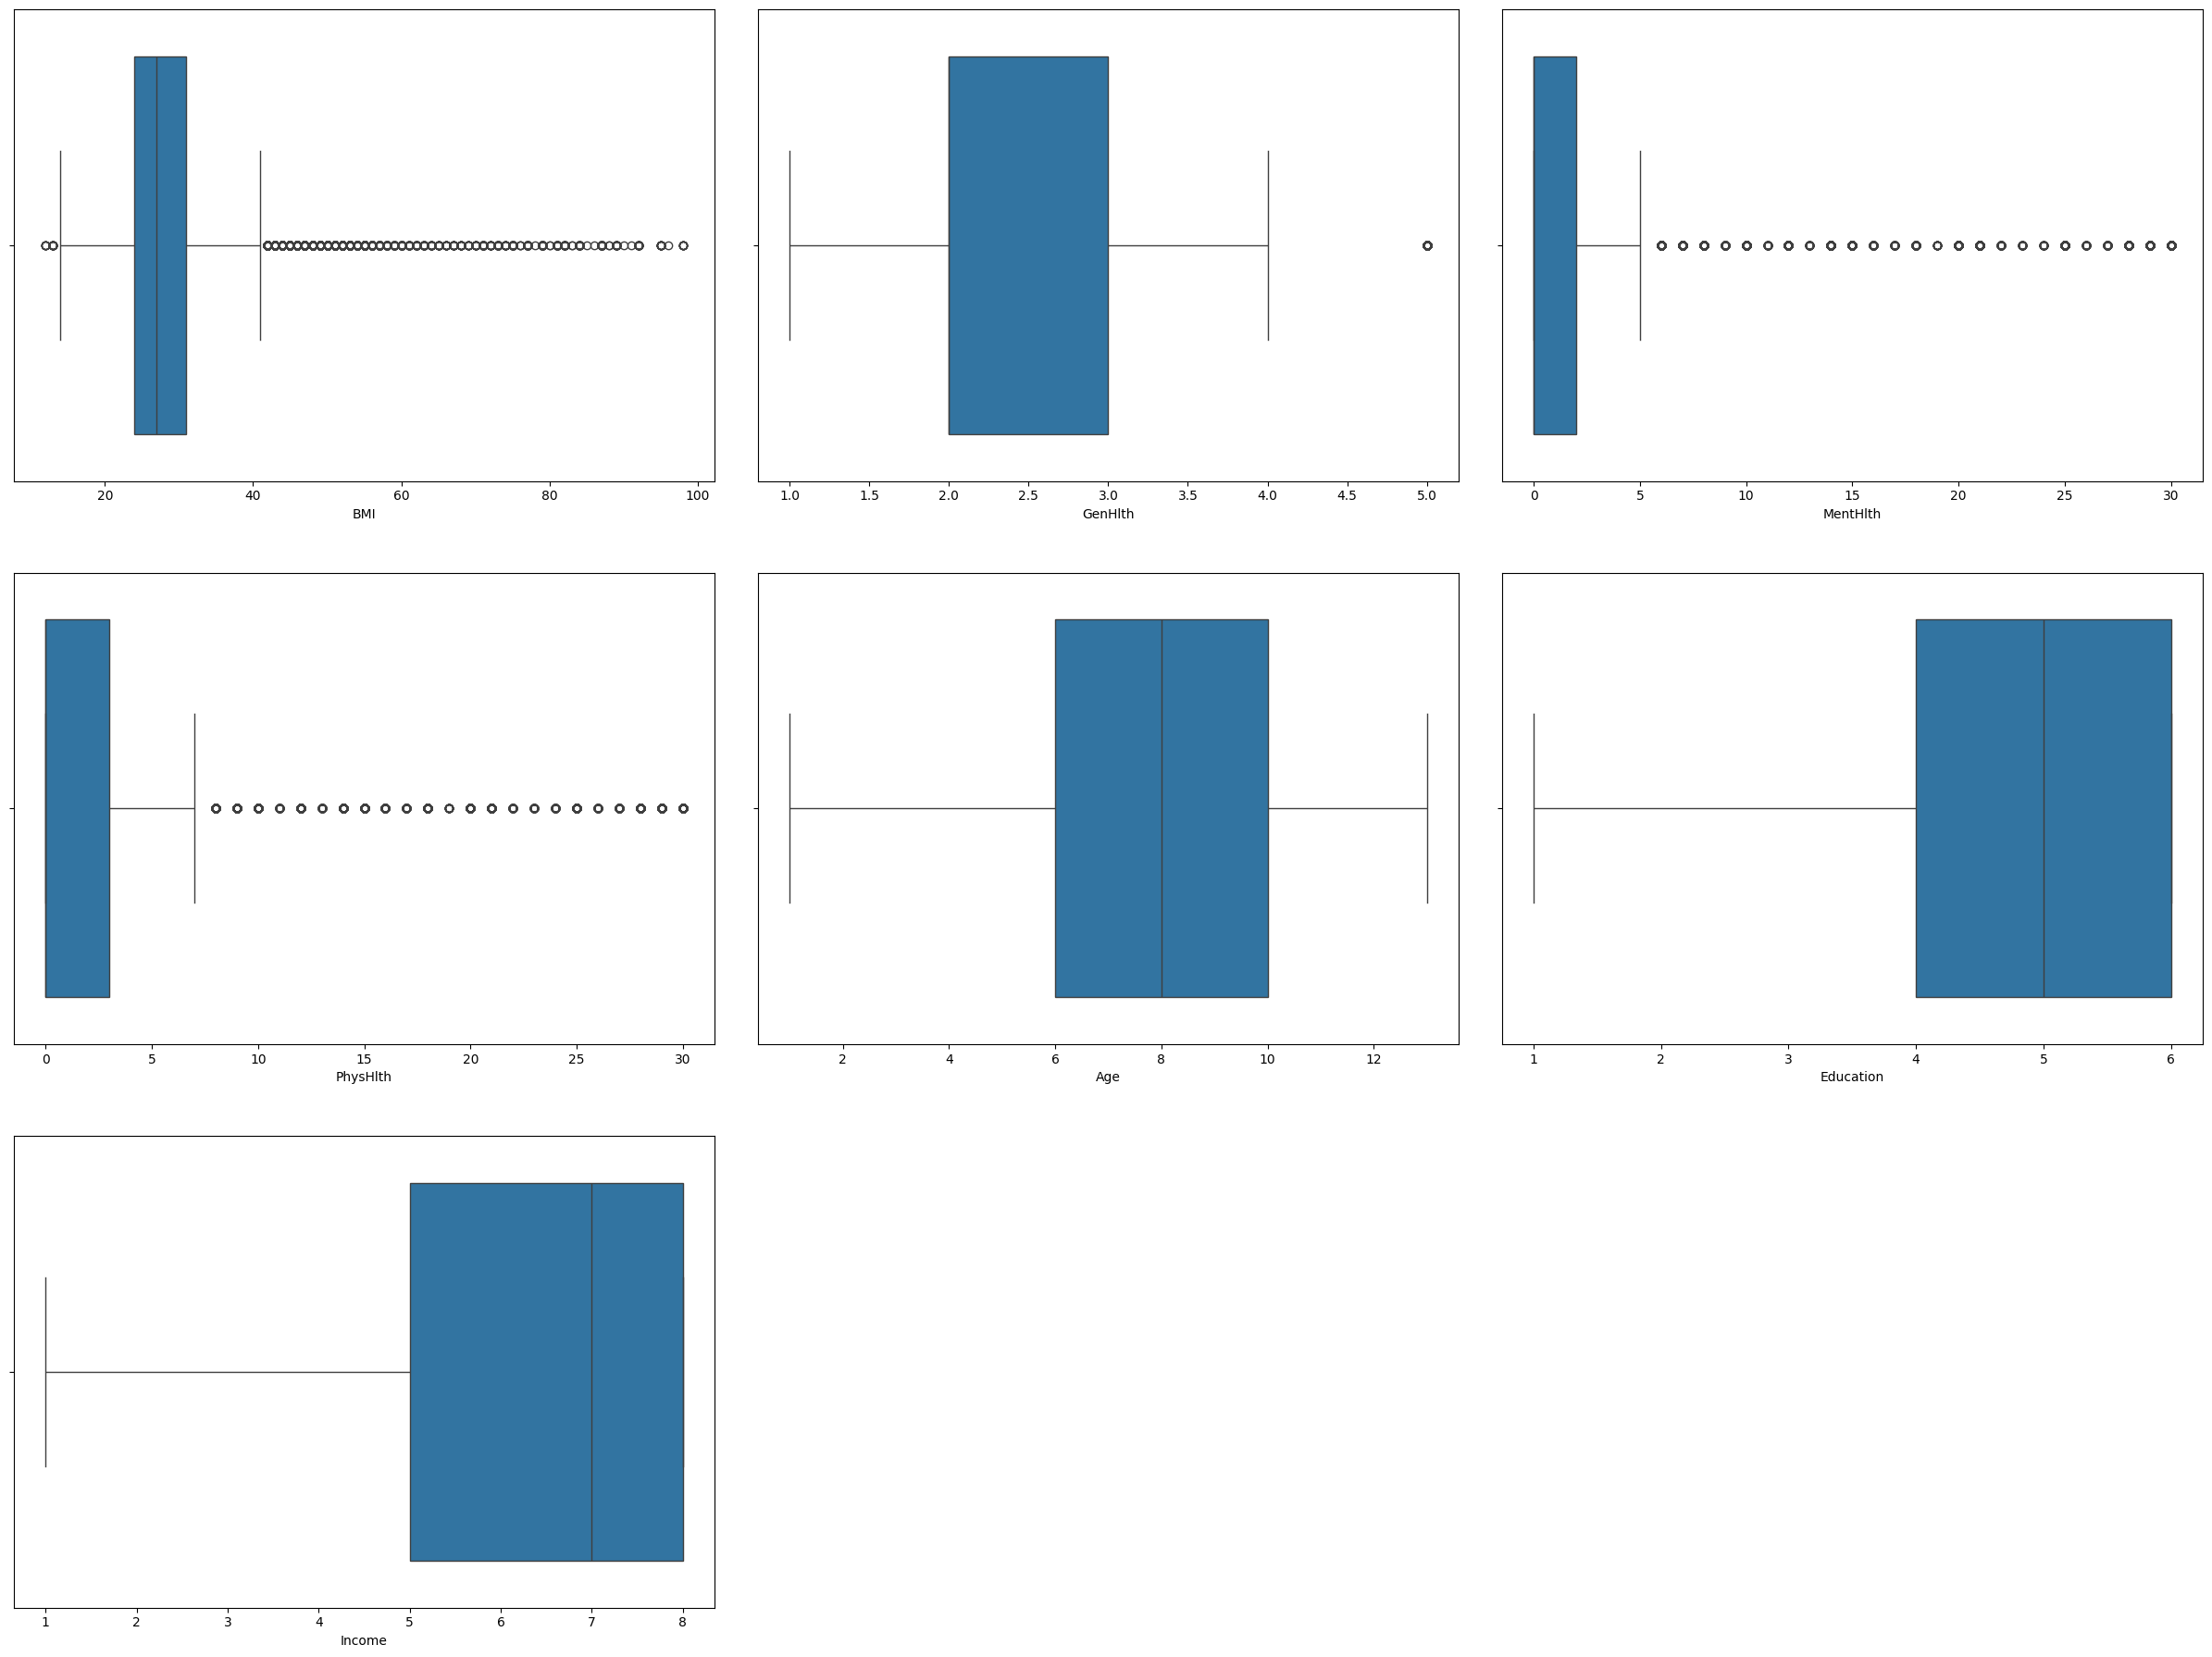

In [ ]:
data = pd.read_csv('/kaggle/input/diabetes-health-indicators-dataset/diabetes_binary_health_indicators_BRFSS2015.csv')
print(data.shape)
print(data.info())
print(data.describe())
print(data.nunique())
print(data.duplicated().sum())

cols = ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']
fig, axes = plt.subplots(3, 3, figsize=(24, 18))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.boxplot(x=col, data=data, ax=ax)

for ax in axes[len(cols):]:
    ax.axis('off')

plt.tight_layout(h_pad=4, w_pad=3)
plt.show()


# **OBSERVACIONES**

DATASET: 253680 instancias y 22 columnas

VALORES NULOS: NO HAY VALORES NULOS EN NINGUNA INSTANCIA

TIPO DE VARIABLES: las variables que conforman son de valor numérico flotante (float). Aunque la mayoría representan variables categóricas nominales, acompañadas por algunas variables numéricas discretas/continuas como la edad o el IMC.

In [ ]:
variables = ['BMI', 'MentHlth', 'PhysHlth']
filas = []

for v in variables:
    s = data[v]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lim_inf) | (s > lim_sup)).sum()
    filas.append({
        'Variable': v,
        'Media': s.mean(), 'Mediana': s.median(),
        'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Lím. inf.': lim_inf, 'Lím. sup.': lim_sup,
        'Mín': s.min(), 'Máx': s.max(),
        'Outliers': n_out, '% outliers': 100 * n_out / len(s),
    })

tabla = pd.DataFrame(filas).round(2)
print(tabla.to_string(index=False))

Variable  Media  Mediana   Q1   Q3  IQR  Lím. inf.  Lím. sup.  Mín  Máx  Outliers  % outliers
     BMI  28.38     27.0 24.0 31.0  7.0       13.5       41.5 12.0 98.0      9847        3.88
MentHlth   3.18      0.0  0.0  2.0  2.0       -3.0        5.0  0.0 30.0     36208       14.27
PhysHlth   4.24      0.0  0.0  3.0  3.0       -4.5        7.5  0.0 30.0     40949       16.14


#**Dibujamos el heatmap**

#**REGISTROS DUPLICADOS**

Los registros duplicados se eliminan para evitar que observaciones idénticas tengan una representación mayor en el análisis y reducir el riesgo de que registros repetidos terminen en los conjuntos de train/test.

La eliminación de duplicados permite que cada registro tenga el mismo peso dentro del análisis y evita el DATA LEAK.

In [ ]:
data.duplicated().sum()
data.drop_duplicates(inplace = True)
data.duplicated().sum()
data.shape

(229474, 22)

In [ ]:
#Creamos una copia de data por si queremos modificar sin tocar la original
data2 = data.copy()

# DISTRIBUCION DE LA VARIABLE TARGET

La variable `Diabetes_binary` constituye el objetivo que se busca predecir.

En el conjunto de datos, el valor `0` representa personas sin diabetes y el valor `1` representa personas con prediabetes o diabetes. Analizar su distribución permite conocer el balance entre las clases y determinar si existe un desbalance que deba tenerse en cuenta al momento de evaluar los modelos.

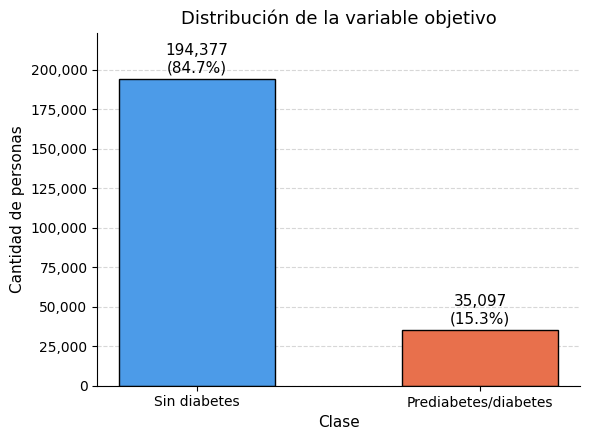

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.5))

conteo = data['Diabetes_binary'].value_counts().sort_index()
total = conteo.sum()
etiquetas = ['Sin diabetes', 'Prediabetes/diabetes']
colores = ['#4C9BE8', '#E8704C']

barras = ax.bar(etiquetas, conteo.values, color=colores, edgecolor='black', width=0.55)

for barra, c in zip(barras, conteo.values):
    ax.text(barra.get_x() + barra.get_width() / 2, c + total * 0.01,
            f'{c:,}\n({c / total:.1%})', ha='center', va='bottom', fontsize=11)

ax.set_ylabel('Cantidad de personas', fontsize=11)
ax.set_xlabel('Clase', fontsize=11)
ax.set_title('Distribución de la variable objetivo', fontsize=13)
ax.set_ylim(0, conteo.max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
sns.despine()

plt.tight_layout()
plt.show()

### **ANALISIS DE CORRELACCIONES ENTRE VARIABLES**

Se utiliza la matriz de correlación de Pearson para analizar la relación lineal entre las variables.

Las mayores correlaciones positivas con `Diabetes_binary` corresponden a:

- `GenHlth`: 0,277
- `HighBP`: 0,254
- `DiffWalk`: 0,205
- `BMI`: 0,205
- `HighChol`: 0,195
- `Age`: 0,177

En cambio, `Income`, `Education` y `PhysActivity` presentan correlaciones negativas con el objetivo.

Estas correlaciones permiten identificar variables potencialmente relevantes para la predicción, pero no implican causalidad. Además, debido a que varias variables son binarias u ordinales, la correlación de Pearson debe interpretarse como una medida exploratoria y no como una prueba definitiva de relación entre las variables.

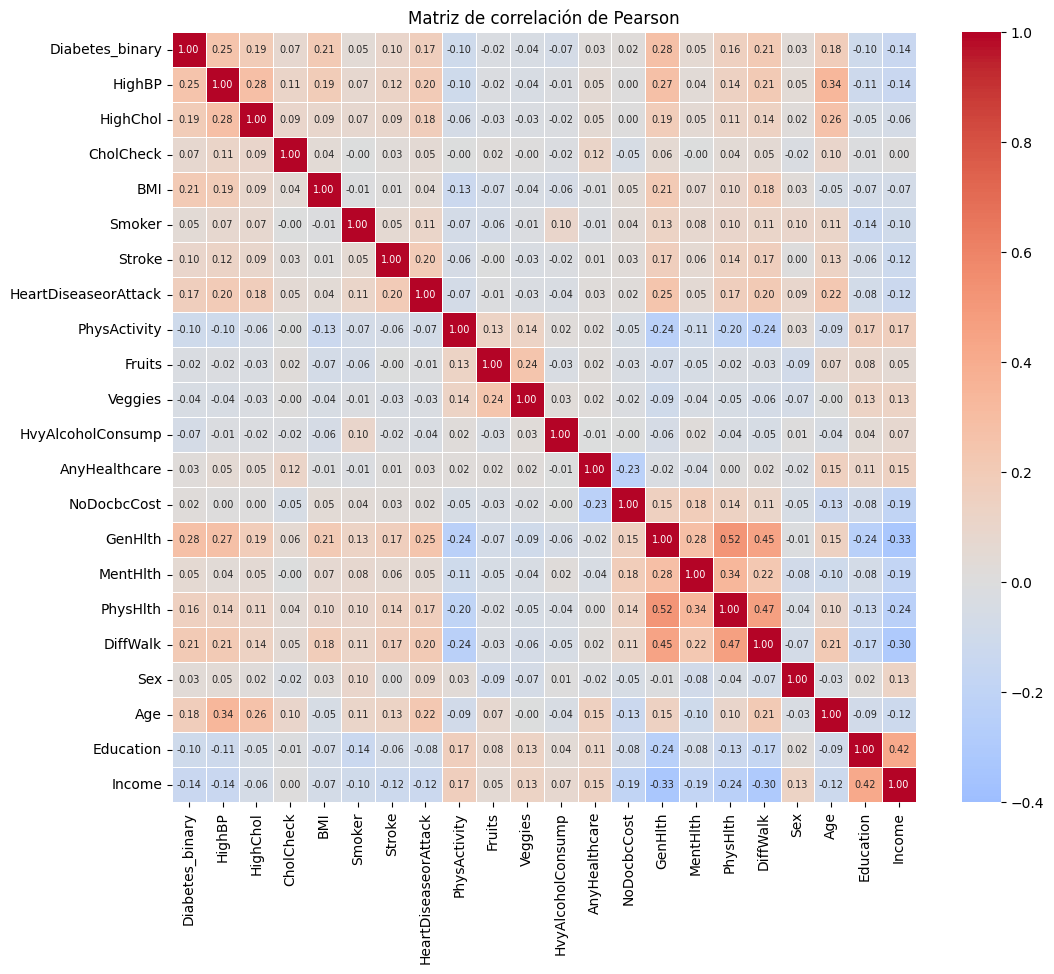

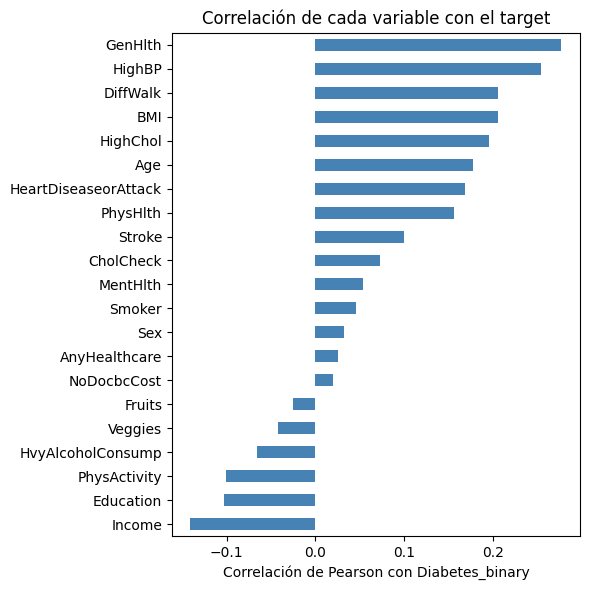

In [ ]:

#2. Calculamos la matriz de correlación de todas las variables
corr = data.corr()

# Figura 3
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', center=0,
            vmin=-0.4, vmax=1, linewidths=0.5, annot_kws={'size': 7})
plt.title("Matriz de correlación de Pearson")
plt.show()

# Figura 4
corr_diab = corr['Diabetes_binary'].drop('Diabetes_binary').sort_values()
ax = corr_diab.plot(kind='barh', figsize=(6, 6), color='steelblue')
ax.set_xlabel('Correlación de Pearson con Diabetes_binary')
ax.set_title('Correlación de cada variable con el target')
plt.tight_layout()
plt.show()

In [ ]:
corr_diab = (
    corr['Diabetes_binary']
    .drop('Diabetes_binary')
    .sort_values(key=abs, ascending=False)
)
print(corr_diab.head(12))

GenHlth                 0.276940
HighBP                  0.254318
DiffWalk                0.205302
BMI                     0.205086
HighChol                0.194944
Age                     0.177263
HeartDiseaseorAttack    0.168213
PhysHlth                0.156211
Income                 -0.140659
Education              -0.102686
PhysActivity           -0.100404
Stroke                  0.099193
Name: Diabetes_binary, dtype: float64


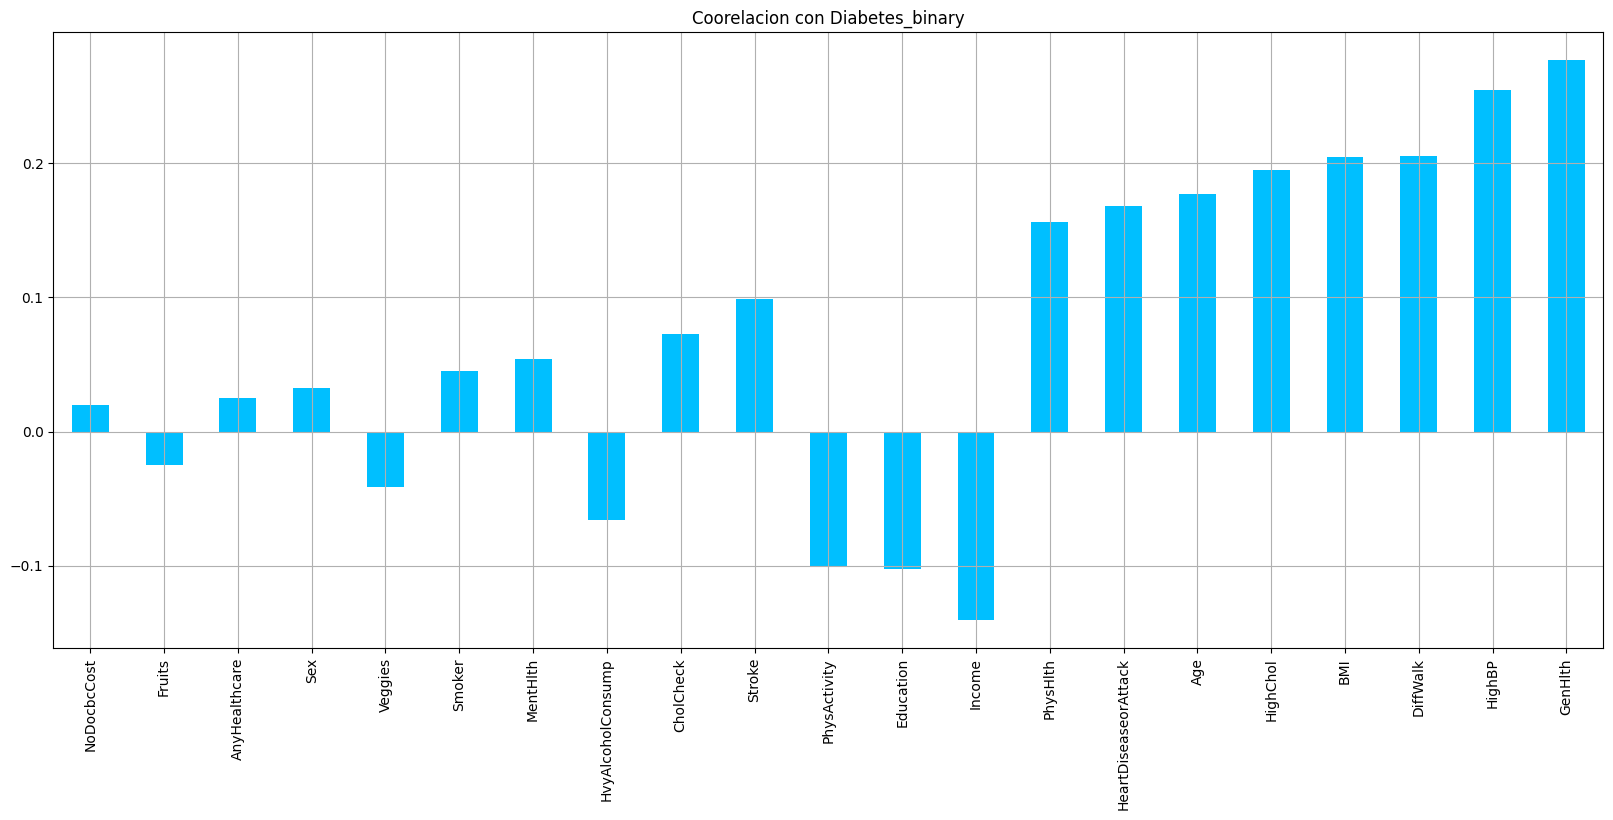

In [ ]:
data.drop('Diabetes_binary', axis=1).corrwith(data.Diabetes_binary).sort_values(key=abs, ascending=True).plot(kind='bar', grid=True, figsize=(20, 8)
, title="Coorelacion con Diabetes_binary",color="Deepskyblue");

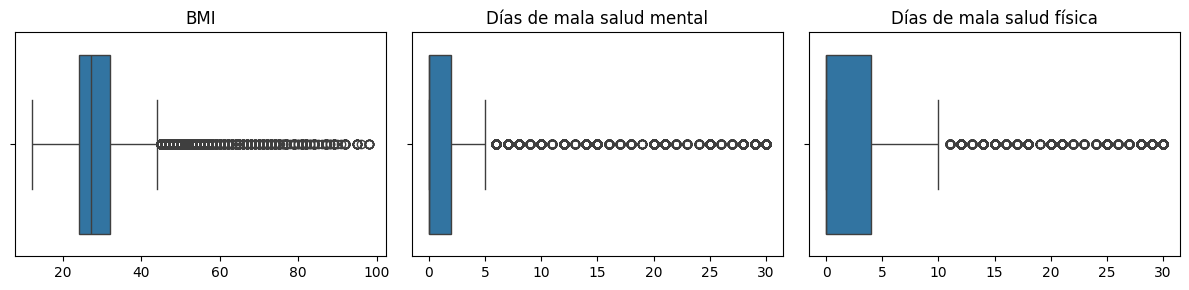

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, tit in zip(axes, ['BMI', 'MentHlth', 'PhysHlth'],
                        ['BMI', 'Días de mala salud mental', 'Días de mala salud física']):
    sns.boxplot(x=data[col], ax=ax)
    ax.set_title(tit)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

### **FACTORES DE RIESGO Y HABITOS**

Se analiza la variable target contra las distintas categorías relacionadas con factores de riesgo, antecedentes y hábitos de salud.

El objetivo es identificar si la proporción de personas con prediabetes o diabetes cambia entre las categorías de cada variable. Diferencias importantes entre categorías pueden indicar que una variable contiene información útil para la predicción.

una diferencia en las proporciones indica asociación, pero no permite afirmar que la variable sea una causa de la diabetes.

In [ ]:
# Diccionarios de etiquetas (valor numérico -> texto en español)
si_no = {0: 'No', 1: 'Sí'}

etiquetas = {
    'Diabetes_binary': {0: 'Sin diabetes', 1: 'Con diabetes o prediabetes'},
    'HighBP': {0: 'Sin presión alta', 1: 'Presión alta'},
    'HighChol': {0: 'Sin colesterol alto', 1: 'Colesterol alto'},
    'CholCheck': {0: 'Sin control de colesterol en 5 años', 1: 'Control de colesterol en 5 años'},
    'Smoker': si_no,
    'Stroke': si_no,
    'HeartDiseaseorAttack': si_no,
    'PhysActivity': si_no,
    'Fruits': si_no,
    'Veggies': si_no,
    'HvyAlcoholConsump': si_no,
    'AnyHealthcare': si_no,
    'NoDocbcCost': si_no,
    'DiffWalk': si_no,
    'Sex': {0: 'Mujer', 1: 'Varon'},
    'GenHlth': {1: 'Excelente', 2: 'Muy buena', 3: 'Buena', 4: 'Regular', 5: 'Mala'},
    'Age': {1: '18 a 24', 2: '25 a 29', 3: '30 a 34', 4: '35 a 39', 5: '40 a 44',
            6: '45 a 49', 7: '50 a 54', 8: '55 a 59', 9: '60 a 64', 10: '65 a 69',
            11: '70 a 74', 12: '75 a 79', 13: '80 o más'},
    'Education': {1: 'Sin escolaridad', 2: 'Primaria', 3: 'Secundaria incompleta',
                  4: 'Secundaria completa', 5: 'Terciario/universitario incompleto',
                  6: 'Universitario completo'},
    'Income': {1: 'Menos de $10.000', 2: '$10.000 a $15.000', 3: '$15.000 a $20.000',
               4: '$20.000 a $25.000', 5: '$25.000 a $35.000', 6: '$35.000 a $50.000',
               7: '$50.000 a $75.000', 8: '$75.000 o más'},
}

for col, mapeo in etiquetas.items():
    # Categórica ordenada: conserva el orden natural en los gráficos
    data2[col] = pd.Categorical(data2[col].map(mapeo),
                                categories=list(mapeo.values()), ordered=True)

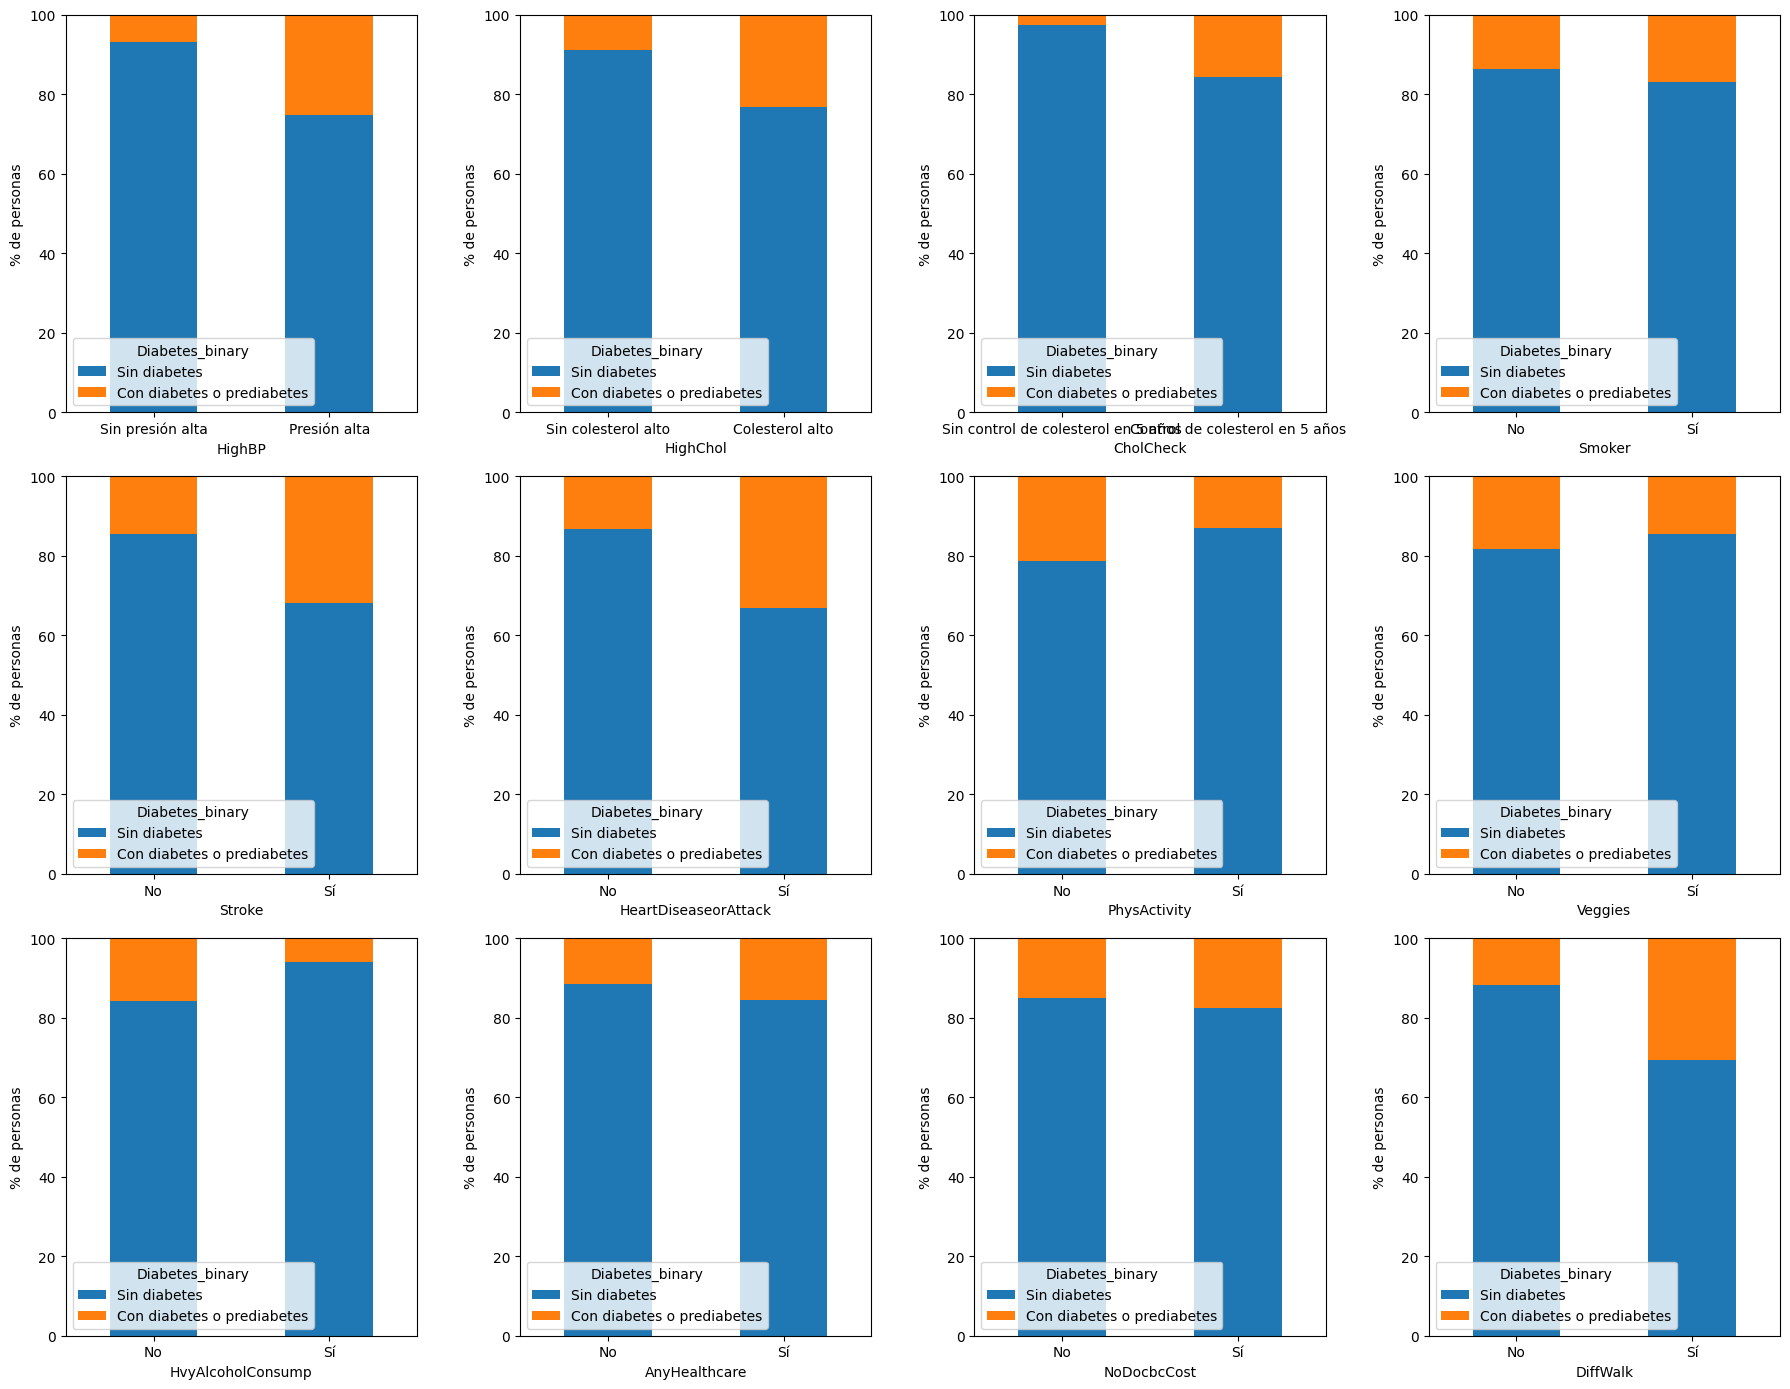

In [ ]:
cols = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker',
    'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk'
]

def create_plot_pivot(data2, x_column):
    """
    Crea una tabla pivote con el % de cada grupo de diabetes dentro de cada categoría.
    """
    _df_plot = data2.groupby(
        [x_column, 'Diabetes_binary'],
        observed=False
    ).size()

    _df_plot = _df_plot.unstack(
        level='Diabetes_binary',
        fill_value=0
    )

    # <- cambio 1: cada barra pasa a sumar 100%
    _df_plot = _df_plot.div(_df_plot.sum(axis=1), axis=0) * 100

    return _df_plot


fig, ax = plt.subplots(3, 4, figsize=(18, 14))

ax = ax.flatten()

for i in range(len(cols)):
    create_plot_pivot(data2, cols[i]).plot(
        kind='bar',
        stacked=True,
        ax=ax[i]
    )

    ax[i].set_xlabel(cols[i])
    ax[i].set_ylabel('% de personas')   # <- cambio 2
    ax[i].set_ylim(0, 100)
    ax[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**responde: ¿las personas con diabetes se reparten distinto que las demás según cada factor de riesgo o hábito? Si en una variable la proporción de diabetes es muy distinta entre “Sí” y “No”, esa variable probablemente ayude a predecir el target. Si es casi igual, probablemente aporte poco.**


OBJETIVOS:


1.   Anticipar la selección de variables.
2.   Justificar el preprocesamiento y las métricas
3.   Tener hipótesis para contrastar después.



### RELACION ENTRE EDAD Y DIABETES

 ¿la proporción de personas con prediabetes o diabetes cambia entre los grupos de edades?

El gráfico muestra que cuando aumenta la edad. Hay una tendencia creciente que indicaría una asociación positiva entre la edad y el target.

Esta variable también resulta relevante para el modelado, ya que puede aportar información predictiva adicional junto con otras variables relacionadas con el estado de salud.

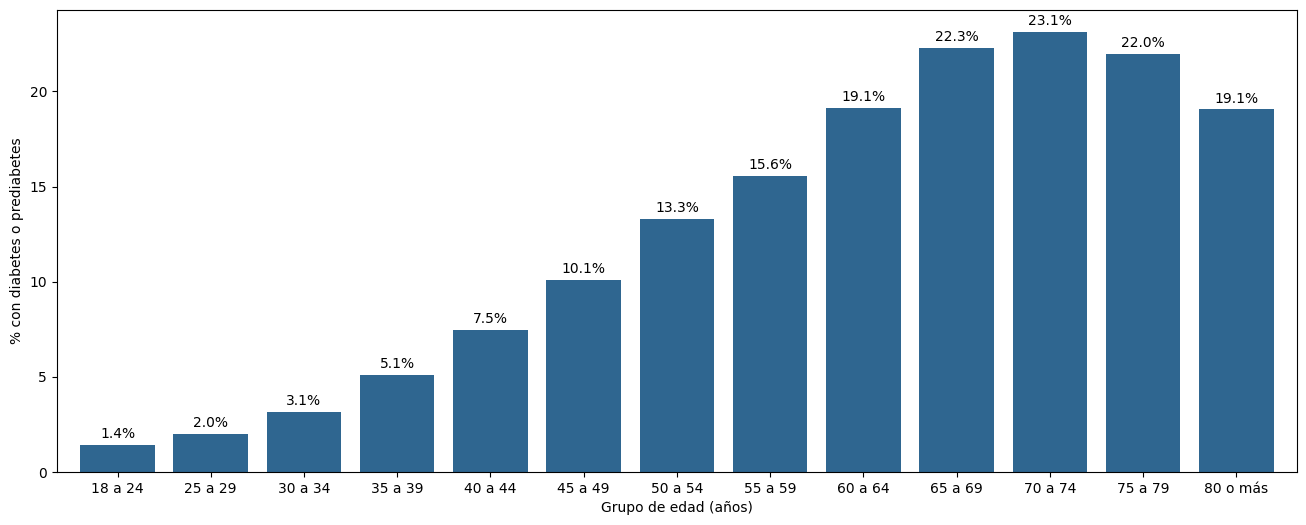

In [ ]:
pct = pd.crosstab(
    data2['Age'],
    data2['Diabetes_binary'],
    normalize='index'
)['Con diabetes o prediabetes'] * 100

ax = pct.plot(
    kind='bar',
    figsize=(16, 6),
    color='#2F6690',
    width=0.8
)

ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.xlabel('Grupo de edad (años)')
plt.ylabel('% con diabetes o prediabetes')
plt.xticks(rotation=0)
plt.show()

### RELACION ENTRE NIVEL EDUCATIVO Y DIABETES

¿Las personas con prediabetes o diabetes varía según el nivel educativo?

El porcentaje mostrado corresponde a la proporción de personas con prediabetes o diabetes dentro de cada categoría educativa. La línea horizontal representa el promedio general del conjunto de datos y permite comparar cada categoría con la tasa global.

Se observa una asociación entre el nivel educativo y el objetivo: los niveles educativos más bajos presentan, en general, una mayor proporción de personas con prediabetes o diabetes.

Sin embargo, esta relación no debe interpretarse como causal. El nivel educativo puede estar relacionado con otras variables presentes en el conjunto de datos, como el ingreso, la edad y el acceso a la atención médica.

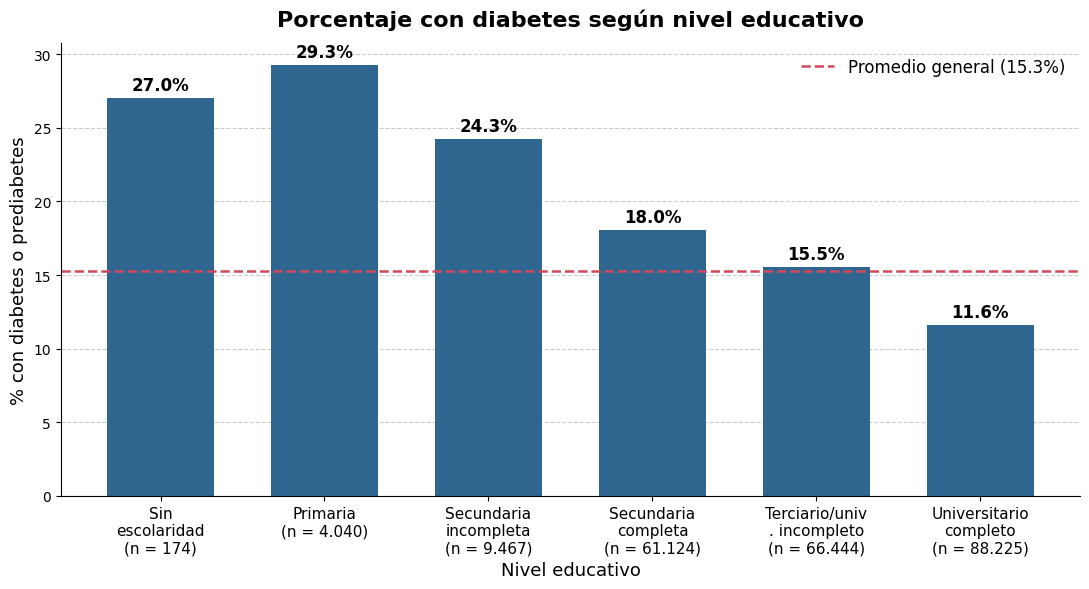

In [ ]:
niveles = ['Sin escolaridad', 'Primaria', 'Secundaria incompleta',
           'Secundaria completa', 'Terciario/univ. incompleto', 'Universitario completo']

g = data.groupby('Education')['Diabetes_binary'].agg(['mean', 'size'])
pct = g['mean'] * 100
tasa_global = data['Diabetes_binary'].mean() * 100

fig, ax = plt.subplots(figsize=(11, 6))
barras = ax.bar(range(6), pct.values, color='#2F6690', width=0.65)
ax.bar_label(barras, labels=[f'{p:.1f}%' for p in pct], padding=3,
             fontsize=12, fontweight='bold')
ax.axhline(tasa_global, color='#D1495B', ls='--', lw=1.8,
           label=f'Promedio general ({tasa_global:.1f}%)')

ax.set_xticks(range(6))
ax.set_xticklabels([f'{textwrap.fill(n, 14)}\n(n = {t:,})'.replace(',', '.')
                    for n, t in zip(niveles, g['size'])], fontsize=11)
ax.set_title('Porcentaje con diabetes según nivel educativo', fontsize=16, fontweight='bold', pad=12)
ax.set_xlabel('Nivel educativo', fontsize=13)
ax.set_ylabel('% con diabetes o prediabetes', fontsize=13)
ax.yaxis.grid(True, color='gray', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.show()

### RELACION ENTRE INGRESOS Y DIABETES

¿ la proporción de personas con prediabetes o diabetes varía según el nivel de ingresos?

La comparación con el promedio general permite ver si hay niveles de ingresos que presentan una proporción superior o inferior a la tasa global.

Se observa que la menor proporción de prediabetes o diabetes esta en los ingreso más altos. Sin embargo, esta relación debe interpretarse como una asociación y no como causalidad.

El ingreso puede estar relacionado con otras variables del conjunto de datos, especialmente educación, edad, acceso a la atención médica y hábitos de salud. Por este motivo, su efecto individual deberá evaluarse posteriormente mediante los modelos predictivos.

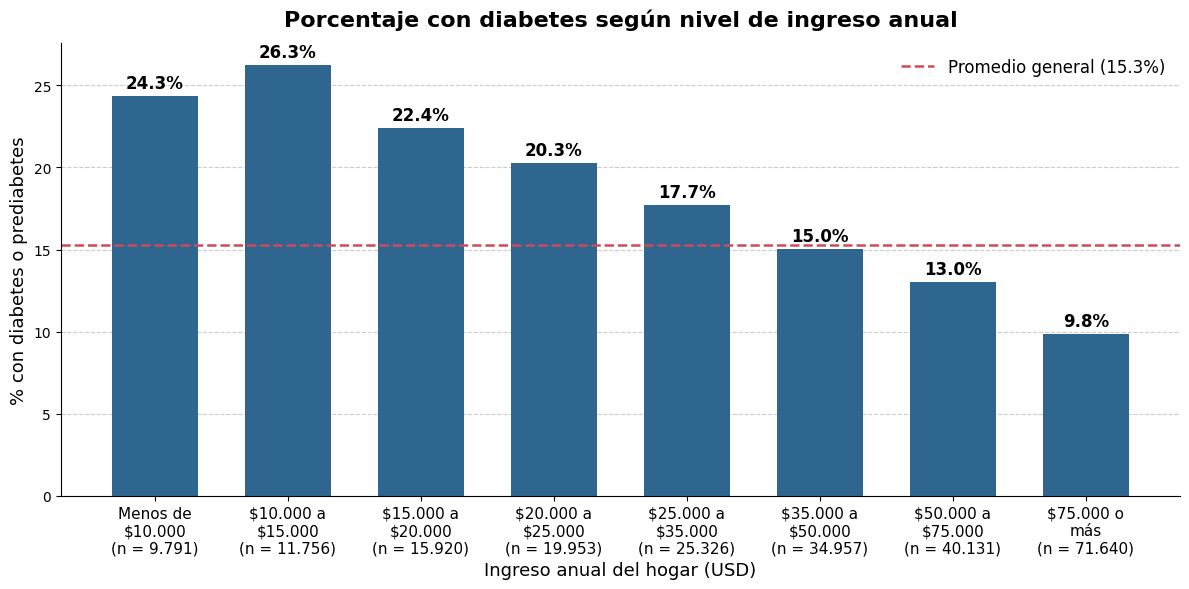

In [ ]:
def grafico_pct_diabetes(data, col, etiquetas, titulo, xlabel):
    g = data.groupby(col)['Diabetes_binary'].agg(['mean', 'size'])
    pct = g['mean'] * 100
    tasa_global = data['Diabetes_binary'].mean() * 100

    fig, ax = plt.subplots(figsize=(12, 6))
    barras = ax.bar(range(len(pct)), pct.values, color='#2F6690', width=0.65)
    ax.bar_label(barras, labels=[f'{p:.1f}%' for p in pct], padding=3,
                 fontsize=12, fontweight='bold')
    ax.axhline(tasa_global, color='#D1495B', ls='--', lw=1.8,
               label=f'Promedio general ({tasa_global:.1f}%)')

    ax.set_xticks(range(len(pct)))
    ax.set_xticklabels([f'{textwrap.fill(e, 12)}\n(n = {n:,})'.replace(',', '.')
                        for e, n in zip(etiquetas, g['size'])], fontsize=11)
    ax.set_title(titulo, fontsize=16, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel('% con diabetes o prediabetes', fontsize=13)
    ax.yaxis.grid(True, color='gray', linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=12)
    plt.tight_layout()
    plt.show()


ingresos = ['Menos de $10.000', '$10.000 a $15.000', '$15.000 a $20.000', '$20.000 a $25.000',
            '$25.000 a $35.000', '$35.000 a $50.000', '$50.000 a $75.000', '$75.000 o más']

grafico_pct_diabetes(data, 'Income', ingresos,
                     'Porcentaje con diabetes según nivel de ingreso anual',
                     'Ingreso anual del hogar (USD)')

### RELACION ENTRE INDICE DE MASA CORPORAL (BMI) CON DIABETES

El histograma permite comparar la distribución del índice de masa corporal (BMI) entre las personas sin diabetes y aquellas con prediabetes o diabetes.

Se utiliza `stat='density'` y `common_norm=False`, por lo que cada grupo se representa de manera independiente y puede compararse la forma de sus distribuciones sin que el tamaño diferente de los grupos determine la altura de las curvas.

Se observa que la distribución del BMI presenta diferencias entre ambos grupos, con una mayor concentración de valores elevados en el grupo con prediabetes o diabetes.

La relación observada representa una asociación y no permite establecer causalidad. Además, el BMI puede estar relacionado con otras variables como edad, actividad física y presión arterial.

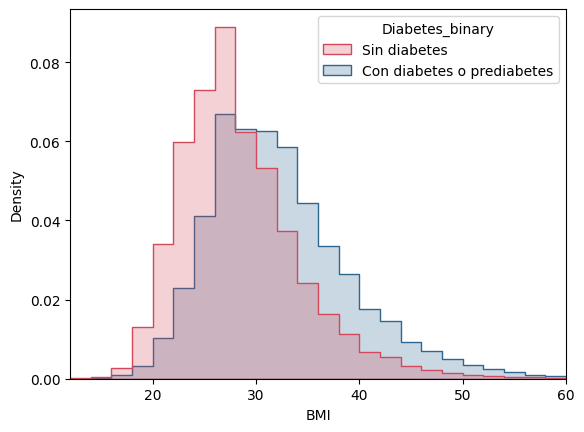

In [ ]:
#count plot to see numbers of Diabetic and non Diabetic patient of Group two BMI

sns.histplot(data=data2, x='BMI', hue='Diabetes_binary', stat='density',
             common_norm=False, binwidth=2, element='step', palette=['#D1495B', '#2F6690'])
plt.xlim(12, 60)
plt.show()


### RELACION ENTRE SALUD MENTAL CON DIABETES

Se analiza si la proporción de personas con prediabetes o diabetes varía según la cantidad de días de mala salud mental reportados durante el último mes.

Para facilitar la interpretación, los valores se agrupan en cuatro categorías: 0 días, 1 a 13 días, 14 a 29 días y 30 días.

La proporción de prediabetes o diabetes presenta diferencias entre los grupos, aunque la tendencia no es completamente uniforme. Por este motivo, `MentHlth` se considera una variable que puede contener información predictiva, pero cuya utilidad deberá comprobarse posteriormente mediante los modelos. Tambien hay que tener en cuenta que es un diagnostico autoreportado

La relación observada representa una asociación y no permite establecer causalidad. Además, esta variable puede estar relacionada con el estado general de salud, la actividad física, la edad y otras condiciones presentes en el conjunto de datos.

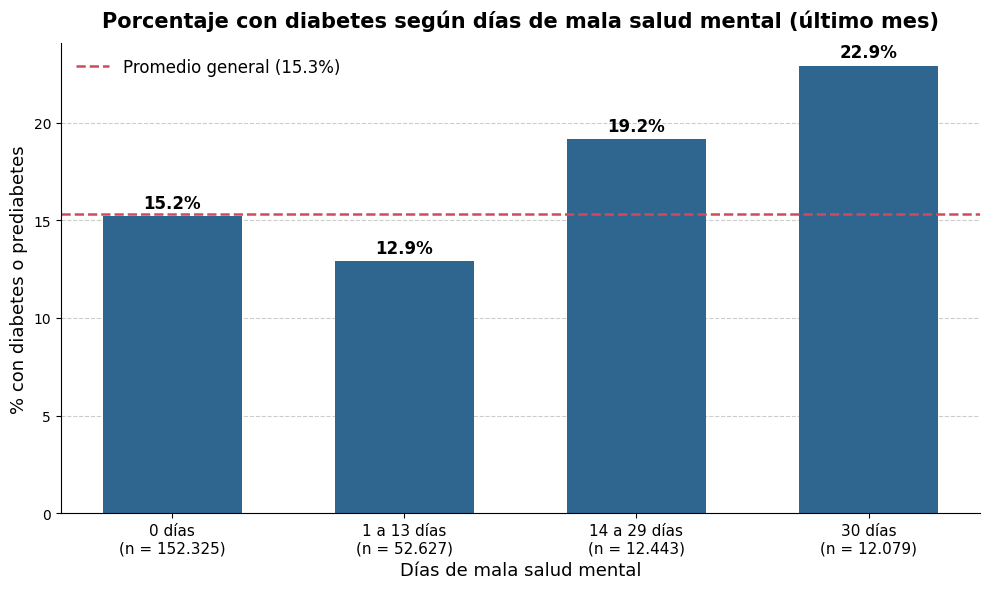

In [ ]:
cortes = [-1, 0, 13, 29, 30]
etiquetas = ['0 días', '1 a 13 días', '14 a 29 días', '30 días']

cat = pd.cut(data['MentHlth'], bins=cortes, labels=etiquetas)
g = data.groupby(cat, observed=False)['Diabetes_binary'].agg(['mean', 'size'])
pct = g['mean'] * 100
tasa_global = data['Diabetes_binary'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar(range(len(pct)), pct.values, color='#2F6690', width=0.6)
ax.bar_label(barras, labels=[f'{p:.1f}%' for p in pct], padding=3,
             fontsize=12, fontweight='bold')
ax.axhline(tasa_global, color='#D1495B', ls='--', lw=1.8,
           label=f'Promedio general ({tasa_global:.1f}%)')

ax.set_xticks(range(len(pct)))
ax.set_xticklabels([f'{e}\n(n = {n:,})'.replace(',', '.') for e, n in zip(etiquetas, g['size'])],
                   fontsize=11)
ax.set_title('Porcentaje con diabetes según días de mala salud mental (último mes)',
             fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Días de mala salud mental', fontsize=13)
ax.set_ylabel('% con diabetes o prediabetes', fontsize=13)
ax.yaxis.grid(True, color='gray', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.show()

CONCLUSIONES:

Más días de mala salud física se asocian con más diabetes. Tiene sentido  porque la diabetes y sus complicaciones afectan la salud física.

La causalidad probablemente va en ambos sentidos. Tener diabetes empeora la salud física, y no solo al revés.

Se mezcla con otras variables. PhysHlth se relaciona con GenHlth, DiffWalk, Age y enfermedad cardíaca. Parte de su señal puede ser compartida con ellas, y eso baja su importancia cuando el modelo ya las tiene.

Es asociación, no causalidad, y los datos son autorreportados.

OBJETIVOS:
PhysHlth se queda. La asociación es lo bastante clara como para no justificar eliminarla.
Anticipá importancia media en el Random Forest y coeficiente positivo en la logística.
Escalala junto con BMI y MentHlth en el pipeline. Con árboles no hace falta.
MentHlth sigue siendo la candidata a evaluar si querés probar eliminar alguna variable con el método de entrenar con y sin ella.



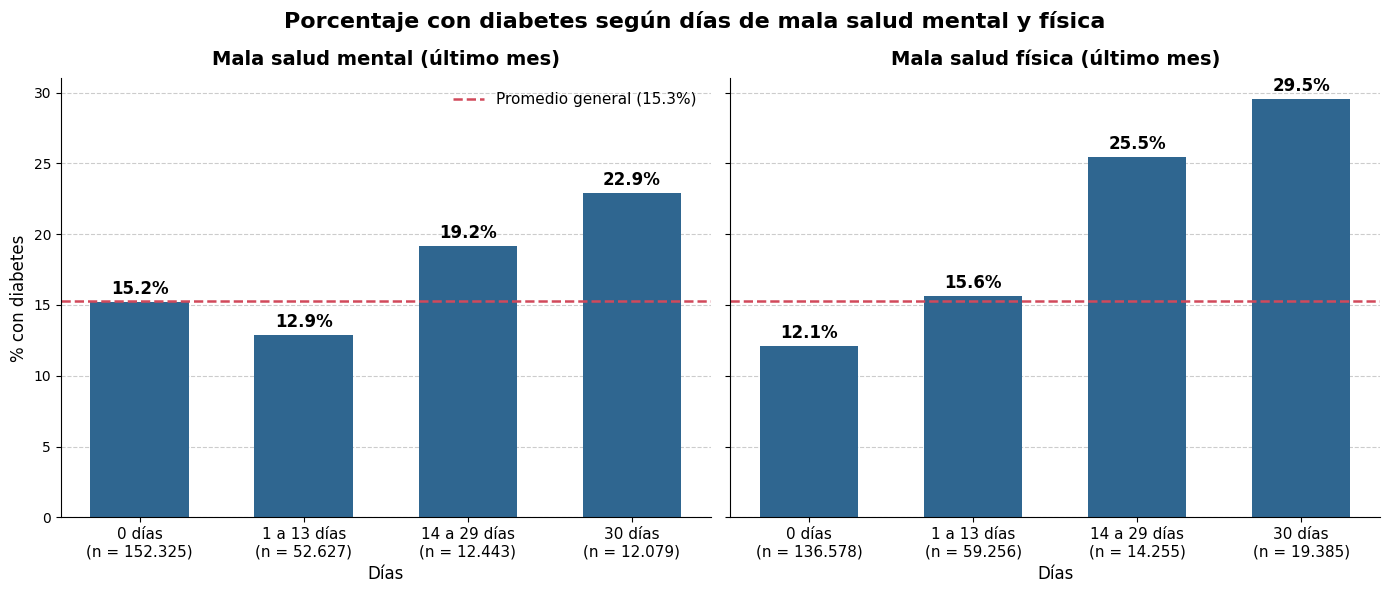

In [ ]:
cortes = [-1, 0, 13, 29, 30]
etiquetas = ['0 días', '1 a 13 días', '14 a 29 días', '30 días']
tasa_global = data['Diabetes_binary'].mean() * 100

variables = [('MentHlth', 'Mala salud mental'), ('PhysHlth', 'Mala salud física')]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, (col, nombre) in zip(axes, variables):
    cat = pd.cut(data[col], bins=cortes, labels=etiquetas)
    g = data.groupby(cat, observed=False)['Diabetes_binary'].agg(['mean', 'size'])
    pct = g['mean'] * 100

    barras = ax.bar(range(len(pct)), pct.values, color='#2F6690', width=0.6)
    ax.bar_label(barras, labels=[f'{p:.1f}%' for p in pct], padding=3,
                 fontsize=12, fontweight='bold')
    ax.axhline(tasa_global, color='#D1495B', ls='--', lw=1.8,
               label=f'Promedio general ({tasa_global:.1f}%)')

    ax.set_xticks(range(len(pct)))
    ax.set_xticklabels([f'{e}\n(n = {n:,})'.replace(',', '.') for e, n in zip(etiquetas, g['size'])],
                       fontsize=11)
    ax.set_title(f'{nombre} (último mes)', fontsize=14, fontweight='bold', pad=10)
    ax.set_xlabel('Días', fontsize=12)
    ax.yaxis.grid(True, color='gray', linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('% con diabetes', fontsize=12)
axes[0].legend(frameon=False, fontsize=11)
fig.suptitle('Porcentaje con diabetes según días de mala salud mental y física',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

¿cómo se relaciona la salud general autopercibida (GenHlth) con tener diabetes?


Conclusiones
El porcentaje sube en cada escalón, de ~3% a ~37%, más de 10 veces. A diferencia de MentHlth o Income, no hay saltos raros ni aplanamientos.

Los niveles 4 y 5 superan por mucho el promedio general (~15%). Entre quienes se califican como “regular” o “mala”, casi 1 de cada 3 tiene diabetes.

Esta variable presenta una asociación particularmente clara con el objetivo. Sin embargo, se trata de una medida subjetiva y autorreportada, por lo que no debe interpretarse como una relación causal.

Se mezcla con otras variables. Está muy ligada a PhysHlth, DiffWalk, Age, HighBP y enfermedad cardíaca.

OBJETIVOS:
Tratamiento: es ordinal y la relación es casi lineal en el código, así que dejarla numérica es razonable y se puede justificar en el informe. No necesita escalado en árboles.

Un cuidado para la consigna 7b: como GenHlth y PhysHlth comparten información, cuando las dos están en el modelo la importancia se reparte entre ellas. Mencionalo si PhysHlth queda con importancia más baja de lo que sugería el EDA.

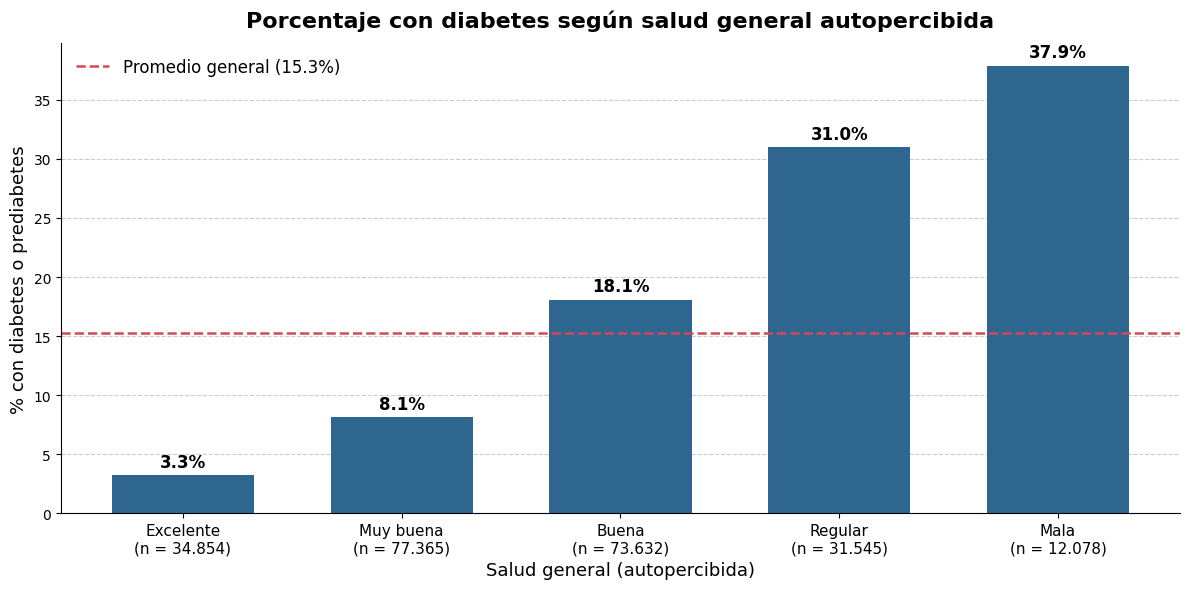

In [ ]:
salud = ['Excelente', 'Muy buena', 'Buena', 'Regular', 'Mala']

grafico_pct_diabetes(data, 'GenHlth', salud,
                     'Porcentaje con diabetes según salud general autopercibida',
                     'Salud general (autopercibida)')



# **Síntesis del análisis exploratorio**

El análisis exploratorio permitió identificar diferentes variables potencialmente relevantes para la predicción de prediabetes o diabetes.

Entre las variables que presentan mayor asociación con el objetivo se encuentran `GenHlth`, `HighBP`, `DiffWalk`, `BMI`, `HighChol`, `Age` y `PhysHlth`. También se observaron asociaciones con `Education`, `Income` y `PhysActivity`, aunque con menor impacto.

Estas relaciones no deben interpretarse como evidencia de causalidad. El objetivo del análisis exploratorio es generar hipótesis y conocer la estructura de los datos, mientras que la utilidad predictiva de cada variable será evaluada posteriormente mediante los modelos de aprendizaje automático.

A partir de este análisis también se identificaron decisiones de preprocesamiento, como el tratamiento de valores faltantes, la eliminación de duplicados y la consideración de las características y escalas de las variables antes del entrenamiento de los modelos.

#MODELO DE REFERENCIA


separamos los datos en dos grupos:

Train (80%): con estos datos se prueban y comparan los modelos.

Test (20%): se guardan sin tocar. Al final sirven para saber cómo le iría al modelo con personas que nunca vio.

Si mirás el test mientras elegís el modelo, el resultado final te queda optimista y no es honesto. Eso es data leakage (fuga de información).

Dentro del train se usa validación cruzada (CV), que es una forma de probar modelos varias veces sin gastar el test.

Quedaron 183.579 filas para train y 45.895 para test.

In [ ]:
# 0) Chequeos: fallan con un mensaje claro si algo quedó mal
assert data.duplicated().sum() == 0, "'data' todavía tiene duplicados: corré la celda de drop_duplicates"
assert data.isna().sum().sum() == 0, "Hay nulos en data"
assert set(data['Diabetes_binary'].unique()) == {0.0, 1.0}, "El target no es 0/1 numérico"

# 1) X e y desde `data` (numérico, sin duplicados)
X = data.drop(columns='Diabetes_binary') #son las variables predictoras, devuelve una copia de la tabla sin esa columna. No toca data.
y = data['Diabetes_binary'].astype(int)
print("X:", X.shape, "| y:", y.shape)

# 2) Test final: 20%, estratificado. No se usa hasta el final.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)


# 3) Verificar que la proporción de positivos se mantuvo en ambos conjuntos
resumen = pd.DataFrame({
    'filas': [len(y), len(y_train), len(y_test)],
    '% positivos': [y.mean()*100, y_train.mean()*100, y_test.mean()*100]
}, index=['Total', 'Train', 'Test']).round(2)
print(resumen)

# 4) Validación cruzada: solo se aplica sobre el train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for k, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    print(f"Fold {k}: train={len(tr):,}  val={len(va):,}  "
          f"% positivos val={y_train.iloc[va].mean()*100:.2f}")

X: (229474, 21) | y: (229474,)
        filas  % positivos
Total  229474        15.29
Train  183579        15.29
Test    45895        15.29
Fold 1: train=146,863  val=36,716  % positivos val=15.29
Fold 2: train=146,863  val=36,716  % positivos val=15.30
Fold 3: train=146,863  val=36,716  % positivos val=15.30
Fold 4: train=146,863  val=36,716  % positivos val=15.30
Fold 5: train=146,864  val=36,715  % positivos val=15.29


#CREAMOS UN MODELO TONTO

creamos un modelo que predice siempre a las persnas como que no tiene diabetes este modelo inutil sirve para compararlo con otros modelos futuros

**¿Cómo medimos a los modelos? Las métricas?**

**El problema del accuracy.** Solo el 15,3% de las personas tiene diabetes. Un "modelo" que siempre responde *"sin diabetes"* acierta el 84,7% de las veces y no detecta a nadie. Por eso el accuracy solo no sirve y usamos varias métricas.

**Las métricas**

| Métrica | Pregunta que responde |
|---|---|
| **Recall** | De las personas que **tienen** diabetes, ¿a cuántas detecté? |
| **Precisión** | De las personas que **marqué** con diabetes, ¿cuántas realmente tienen? |
| **F1** | Un promedio de recall y precisión; baja si alguna de las dos es muy mala |
| **Balanced accuracy** | Promedio del acierto en cada clase; trata igual a sanos y enfermos |
| **ROC-AUC** | Si tomo una persona enferma y una sana al azar, ¿qué tan seguido el modelo le da más riesgo a la enferma? (0,5 = azar, 1 = perfecto) |
| **PR-AUC** | Qué tan bien se mantiene la precisión a medida que se sube el recall (el azar vale 0,153, la proporción de casos) |

Recall, precisión y F1 dependen de un **umbral** (a partir de qué probabilidad el modelo dice "diabetes"). ROC-AUC y PR-AUC **no**: evalúan el ordenamiento de riesgos. Por eso sirven para comparar modelos.

**Criterio del grupo**
1. El objetivo se parece a un **tamizaje**: es más grave dejar escapar un caso (falso negativo) que hacer un estudio de más (falsa alarma). Priorizamos el **recall**, sin marcar a todo el mundo (por eso miramos la precisión).
2. Para **comparar modelos entre sí** usamos **PR-AUC** (con ROC-AUC de apoyo).
3. Accuracy y balanced accuracy se informan solo como contexto.

**Cómo leer "media ± desvío"**: es el promedio de los 5 folds y cuánto varían entre sí. Un desvío chico significa que el resultado es estable.

#cualquier modelo que valga la pena tiene que superar a quien nunca detecta ningún caso

In [ ]:
# 1) Qué métricas calcular en cada fold
scoring = {
    'accuracy':     'accuracy',
    'balanced_acc': 'balanced_accuracy',
    'precision':    make_scorer(precision_score, zero_division=0),
    'recall':       'recall',
    'f1':           'f1',
    'roc_auc':      'roc_auc',
    'pr_auc':       'average_precision',
}

# 2) Función para evaluar cualquier modelo con la misma CV
folds = {}   # guarda el resultado de cada fold para cada modelo

def evaluar(nombre, modelo, Xtr=None):
    Xtr = X_train if Xtr is None else Xtr
    r = cross_validate(modelo, Xtr, y_train, cv=cv, scoring=scoring)
    f = pd.DataFrame({m: r[f'test_{m}'] for m in scoring})   # 5 filas (folds) x 7 métricas
    folds[nombre] = f
    return (f.mean().round(3).astype(str) + ' ± ' + f.std().round(3).astype(str)).rename(nombre)

# 3) Tabla numérica con las medias de todos los modelos evaluados
def tabla_resultados():
    return pd.DataFrame({n: f.mean() for n, f in folds.items()}).T.round(3)

# Prueba: el dummy como piso
print(evaluar('Dummy mayoritaria', DummyClassifier(strategy='most_frequent')))
tabla_resultados()

accuracy        0.847 ± 0.0
balanced_acc      0.5 ± 0.0
precision         0.0 ± 0.0
recall            0.0 ± 0.0
f1                0.0 ± 0.0
roc_auc           0.5 ± 0.0
pr_auc          0.153 ± 0.0
Name: Dummy mayoritaria, dtype: object


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
Dummy mayoritaria,0.847,0.5,0.0,0.0,0.0,0.5,0.153


#PROBAMOS MODELOS DE REFERENCIAS

**Qué aprendimos**
1. **El accuracy engaña**: el modelo tonto saca 0,85 sin detectar a nadie.
4. **El umbral importa**: con el umbral por defecto (0,5) la logística detecta solo el 6% de los casos, aunque ordena igual de bien (mismo PR-AUC). Con `class_weight='balanced'` (que le da más peso a los casos con diabetes) detecta el 67%.
5. **La precisión es baja en todos** (0,25–0,33): de cada 10 personas marcadas, solo 3 aproximadamente tienen diabetes. Es lo normal con pocas variables y 15% de casos, y es el margen de mejora de los modelos siguientes.


Cualquier modelo posterior debe superar estos valores para justificar su complejidad.





In [ ]:
# --- Tablas de resultados ---
def tabla_pm():   # media ± desvío entre folds (para el informe)
    return pd.DataFrame({n: (f.mean().round(3).astype(str) + ' ± ' + f.std().round(3).astype(str))
                         for n, f in folds.items()}).T

display(tabla_pm())

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
Dummy mayoritaria,0.847 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.153 ± 0.0


#Modelo 1: regresión logística simple

#4.1
Hipótesis. Las variables más correlacionadas con el target en el EDA contienen la mayor parte de la información lineal sobre el riesgo de diabetes. Por lo tanto, una regresión logística con pocas de ellas debería superar claramente al benchmark, sin necesidad de usar todas las variables.

La regresión logística se utiliza como primer modelo porque es relativamente sencilla de entrenar e interpretar y permite establecer una referencia de aprendizaje automático para comparar posteriormente con modelos más complejos.

En la versión utilizada para analizar la frontera de decisión se consideran tres variables predictoras: GenHlth (estado general de salud), BMI (índice de masa corporal) y HighBP (presión arterial alta). Estas variables se seleccionaron por su relación con el problema y por permitir visualizar cómo el modelo combina distintos factores para producir una clasificación.

#4.2 TECNICAS DE PREPROCESAMIENTO

Antes de entrenar el modelo, los datos se separan en conjuntos de entrenamiento y prueba. El conjunto de entrenamiento se utiliza para ajustar el modelo y tomar las decisiones necesarias durante el desarrollo; el conjunto de prueba se reserva para evaluar el rendimiento final sobre observaciones que no se utilizaron para entrenarlo.

Para la evaluación durante el desarrollo se utiliza validación cruzada, que permite repetir el entrenamiento y la evaluación sobre diferentes particiones de los datos. Esto reduce la dependencia de una única división y permite estimar la estabilidad del rendimiento.

En el preprocesamiento se contempla la escala de las variables numéricas. Cuando se utiliza StandardScaler, cada variable seleccionada se transforma para que tenga media cercana a cero y desviación estándar cercana a uno. Esto facilita el ajuste de la regresión logística cuando las variables tienen escalas diferentes. Las variables binarias, como HighBP, pueden mantenerse en su codificación original.

El preprocesamiento se incorpora al flujo de entrenamiento para que los parámetros de transformación se calculen utilizando únicamente los datos de entrenamiento de cada partición. De este modo se evita que información de validación o prueba intervenga en el ajuste.

#4.3 TRATAMIENTO DEL DESBALANCE DE CLASES

El conjunto de datos presenta un desbalance entre las clases: las observaciones negativas son más frecuentes que las positivas. En estas condiciones, un modelo puede obtener una exactitud elevada y, al mismo tiempo, no detectar una proporción importante de los casos positivos.

Por esta razón, la evaluación no se basa exclusivamente en accuracy. Se consideran también métricas como precision, recall, F1, ROC-AUC y PR-AUC, que permiten analizar distintos aspectos del rendimiento.

Además, el umbral de clasificación se estudia por separado. La regresión logística estima probabilidades y, para convertirlas en clases, se establece un umbral a partir del cual una observación se clasifica como positiva. El valor predeterminado suele ser 0,5, pero no necesariamente es el más apropiado cuando las clases están desbalanceadas.

#4.4 Objetivo del primer modelo

El propósito de esta primera regresión logística es establecer una referencia de aprendizaje automático, analizar su capacidad para distinguir entre las clases y comprender las limitaciones de una frontera de decisión lineal. Sus resultados se comparan con el benchmark definido anteriormente y sirven como punto de partida para desarrollar un segundo modelo.

In [ ]:
# Variables numéricas/ordinales: se estandarizan. Las binarias pasan sin tocar.
a_escalar = ['BMI', 'MentHlth', 'PhysHlth', 'GenHlth', 'Age', 'Education', 'Income']

def modelo_simple(cols, **kw):
    prep = ColumnTransformer([('esc', StandardScaler(), [c for c in a_escalar if c in cols])],
                             remainder='passthrough')
    return Pipeline([('prep', prep), ('lr', LogisticRegression(max_iter=1000, **kw))])

# 1) Correlación con el target, calculada SOLO sobre train
corr_train = (pd.concat([X_train, y_train.rename('Diabetes_binary')], axis=1)
                .corr()['Diabetes_binary'].drop('Diabetes_binary'))
orden = corr_train.abs().sort_values(ascending=False).index
display(corr_train[orden].head(8).round(3))

# 2) ¿Cuántas variables hacen falta? Se suman de a una y se mira la métrica
curva = []
for k in range(1, 9):
    cols = list(orden[:k])
    r = cross_validate(modelo_simple(cols), X_train[cols], y_train, cv=cv,
                       scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}, n_jobs=-1)
    curva.append({'k': k, 'variable agregada': orden[k-1],
                  'roc_auc': r['test_roc_auc'].mean(), 'pr_auc': r['test_pr_auc'].mean()})
display(pd.DataFrame(curva).round(3))

# 3) Modelo 1 con las 4 más correlacionadas
cols_m1 = list(orden[:3])
print('Variables del modelo 1:', cols_m1)
evaluar('Modelo 1: LogReg por defecto (4 var.)', modelo_simple(cols_m1), X_train[cols_m1])
evaluar('Modelo 1b: LogReg por defecto + balanced (4 var.)',
        modelo_simple(cols_m1, class_weight='balanced'), X_train[cols_m1])
display(tabla_pm())

,Diabetes_binary
GenHlth,0.275
HighBP,0.254
BMI,0.205
DiffWalk,0.204
HighChol,0.194
Age,0.178
HeartDiseaseorAttack,0.169
PhysHlth,0.155


,k,variable agregada,roc_auc,pr_auc
0,1,GenHlth,0.709,0.266
1,2,HighBP,0.757,0.319
2,3,BMI,0.776,0.369
3,4,DiffWalk,0.777,0.371
4,5,HighChol,0.787,0.390
5,6,Age,0.799,0.395
6,7,HeartDiseaseorAttack,0.800,0.398
7,8,PhysHlth,0.801,0.398


Variables del modelo 1: ['GenHlth', 'HighBP', 'BMI']


,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
Dummy mayoritaria,0.847 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.153 ± 0.0
Modelo 1: LogReg por defecto (4 var.),0.849 ± 0.001,0.539 ± 0.001,0.53 ± 0.014,0.093 ± 0.002,0.158 ± 0.003,0.776 ± 0.001,0.369 ± 0.003
Modelo 1b: LogReg por defecto + balanced (4 var.),0.696 ± 0.001,0.707 ± 0.002,0.297 ± 0.001,0.722 ± 0.006,0.421 ± 0.002,0.776 ± 0.001,0.367 ± 0.003


# 5.1 EVALUACION DEL MODELO



La evaluación se realiza mediante métricas de clasificación y representaciones gráficas que permiten analizar tanto la capacidad del modelo para distinguir las clases como los errores que comete.

Durante el desarrollo se utiliza validación cruzada sobre el conjunto de entrenamiento. Esta metodología divide los datos en varias particiones y repite el proceso de ajuste y evaluación, de modo que cada partición pueda utilizarse para validar el modelo. Se analizan los promedios y la variabilidad de las métricas entre las particiones.

Una vez seleccionado el procedimiento, se evalúa el modelo final sobre el conjunto de prueba reservado. Este conjunto no debe utilizarse para elegir variables, ajustar el umbral ni tomar decisiones sobre el modelo, ya que hacerlo produciría una estimación demasiado optimista de su rendimiento.

Dado que las clases están desbalanceadas, se consideran las siguientes métricas:

Accuracy: proporción total de predicciones correctas.

Precision: proporción de predicciones positivas que realmente pertenecen a la clase positiva.

Recall: proporción de casos positivos reales que el modelo logra identificar.

F1: media armónica entre precision y recall.

ROC-AUC: mide la capacidad del modelo para ordenar los casos positivos por encima de los negativos a distintos umbrales.

PR-AUC o Average Precision (AP): resume el comportamiento de precision y recall para distintos umbrales y resulta especialmente informativa cuando la clase positiva es minoritaria.

También se analiza la matriz de confusión, que permite distinguir entre verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos.

#5.2. Elección del umbral de clasificación

La regresión logística produce una probabilidad estimada para cada observación. Para convertir esa probabilidad en una clase, se define un umbral: si la probabilidad alcanza o supera ese valor, se predice la clase positiva; en caso contrario, se predice la clase negativa.

El umbral predeterminado de 0,5 no siempre resulta adecuado en un conjunto desbalanceado. Por ello, se analizó cómo cambian precision, recall y F1 al modificarlo.

En los experimentos realizados se seleccionó un umbral cercano a 0,208, asociado a un valor elevado de F1 en la curva evaluada. Esta elección representa un compromiso entre detectar casos positivos y evitar falsas alarmas. El umbral se debe seleccionar utilizando únicamente el conjunto de entrenamiento y su validación cruzada, sin consultar los resultados del conjunto de prueba.

La elección no es universal: si el objetivo principal fuera reducir los falsos negativos, podría preferirse un umbral menor para aumentar el recall, aceptando que también se incrementarían los falsos positivos.



Umbral elegido (máx. F1 en CV sobre train): 0.205


,umbral,precision,recall,f1,balanced_acc
"Umbral 0,5 (por defecto)",0.500,0.529,0.093,0.158,0.539
Umbral máx. F1,0.205,0.335,0.608,0.432,0.695


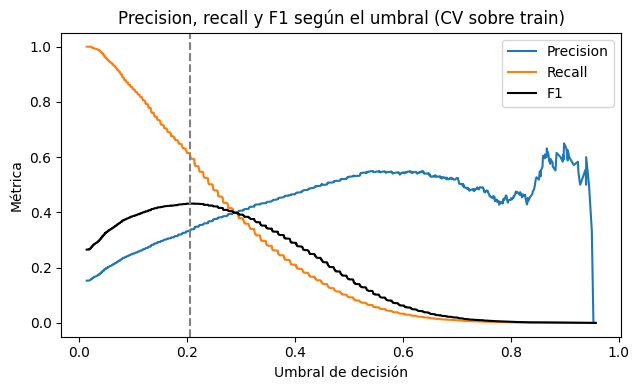

In [ ]:
m1 = modelo_simple(cols_m1)          # Modelo 1: logística por defecto, 3 variables

# Probabilidades "fuera de muestra": cada fila de train es predicha por un modelo que NO la vio
proba_oof = cross_val_predict(m1, X_train[cols_m1], y_train, cv=cv, method='predict_proba')[:, 1]

prec, rec, thr = precision_recall_curve(y_train, proba_oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
umbral = thr[np.argmax(f1[:-1])]                 # umbral que maximiza F1 en train (CV)
print(f'Umbral elegido (máx. F1 en CV sobre train): {umbral:.3f}')

def fila(p, y, t, nombre):
    pred = (p >= t).astype(int)
    return pd.Series({'umbral': round(t, 3),
                      'precision': precision_score(y, pred, zero_division=0),
                      'recall': recall_score(y, pred),
                      'f1': f1_score(y, pred),
                      'balanced_acc': balanced_accuracy_score(y, pred)}, name=nombre)

tabla_umbral = pd.DataFrame([fila(proba_oof, y_train, 0.5, 'Umbral 0,5 (por defecto)'),
                             fila(proba_oof, y_train, umbral, 'Umbral máx. F1')]).round(3)
display(tabla_umbral)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(thr, prec[:-1], label='Precision')
ax.plot(thr, rec[:-1], label='Recall')
ax.plot(thr, f1[:-1], label='F1', color='k')
ax.axvline(umbral, ls='--', color='gray')
ax.set_xlabel('Umbral de decisión'); ax.set_ylabel('Métrica'); ax.legend()
ax.set_title('Precision, recall y F1 según el umbral (CV sobre train)')
plt.tight_layout(); plt.show()

#5.3. Interpretación de precision, recall y F1 según el umbral

Figura 1. Precision, recall y F1 según el umbral de clasificación. La figura muestra cómo cambian las tres métricas al modificar el umbral utilizado para convertir las probabilidades en clases.

Al aumentar el umbral, el modelo exige una probabilidad más alta para predecir la clase positiva. En general, esto reduce el número de observaciones clasificadas como positivas y tiende a disminuir el recall, mientras que la precision puede aumentar.

Con el umbral seleccionado, cercano a 0,208, los resultados obtenidos durante el análisis indican un recall aproximado de 0,60 y una precision cercana a 0,33. Esto significa que se identifican alrededor de seis de cada diez casos positivos, pero solo cerca de un tercio de las predicciones positivas corresponde a casos positivos reales.

La curva de F1 presenta una zona relativamente estable alrededor de su máximo, lo que indica que pequeñas variaciones del umbral en esa región no modifican drásticamente el compromiso entre precision y recall. Sin embargo, el umbral elegido depende del objetivo del proyecto y no debe considerarse automáticamente el mejor para cualquier aplicación.

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
"Benchmark (siempre ""no"")",0.847,0.500,0.000,0.000,0.00,0.50,0.153
Modelo 1 (umbral elegido),0.754,0.704,0.337,0.631,0.44,0.78,0.377


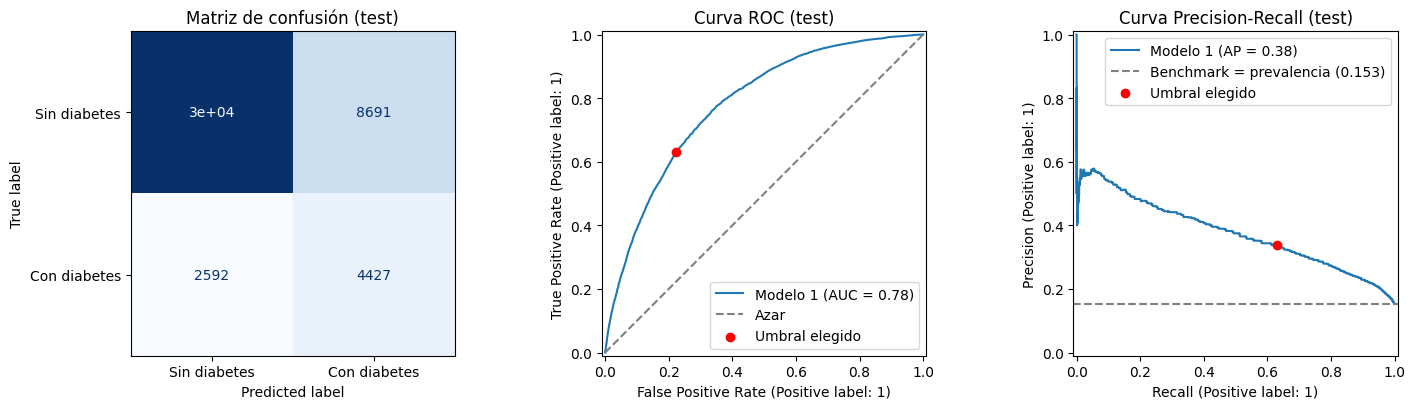

In [ ]:


m1.fit(X_train[cols_m1], y_train)                      # se entrena con TODO train
p_test = m1.predict_proba(X_test[cols_m1])[:, 1]
pred_test = (p_test >= umbral).astype(int)

prev = y_test.mean()
res = pd.DataFrame({
    'Benchmark (siempre "no")': {'accuracy': 1 - prev, 'balanced_acc': 0.5, 'precision': 0.0, 'recall': 0.0,
                                 'f1': 0.0, 'roc_auc': 0.5, 'pr_auc': prev},
    'Modelo 1 (umbral elegido)': {'accuracy': accuracy_score(y_test, pred_test),
                                  'balanced_acc': balanced_accuracy_score(y_test, pred_test),
                                  'precision': precision_score(y_test, pred_test),
                                  'recall': recall_score(y_test, pred_test),
                                  'f1': f1_score(y_test, pred_test),
                                  'roc_auc': roc_auc_score(y_test, p_test),
                                  'pr_auc': average_precision_score(y_test, p_test)}}).T.round(3)
display(res)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['Sin diabetes', 'Con diabetes'],
                                        cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Matriz de confusión (test)')

RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[1], name='Modelo 1')
axes[1].plot([0, 1], [0, 1], ls='--', color='gray', label='Azar')
axes[1].scatter(((p_test >= umbral) & (y_test == 0)).sum() / (y_test == 0).sum(), recall_score(y_test, pred_test),
                color='red', zorder=3, label='Umbral elegido')
axes[1].legend(); axes[1].set_title('Curva ROC (test)')

PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[2], name='Modelo 1')
axes[2].axhline(prev, ls='--', color='gray', label=f'Benchmark = prevalencia ({prev:.3f})')
axes[2].scatter(recall_score(y_test, pred_test), precision_score(y_test, pred_test),
                color='red', zorder=3, label='Umbral elegido')
axes[2].legend(); axes[2].set_title('Curva Precision-Recall (test)')
plt.tight_layout(); plt.show()

#5.4. Matriz de confusión y curvas ROC y Precision-Recall

Figura 2. Matriz de confusión del modelo sobre el conjunto de prueba. La matriz compara las clases reales con las predicciones realizadas utilizando el umbral seleccionado.

En los resultados obtenidos, el modelo identificó 4.427 casos positivos correctamente y dejó sin detectar 2.592 casos positivos. A su vez, clasificó erróneamente como positivos 8.691 casos negativos. Esto evidencia que el modelo logra detectar una parte importante de los casos positivos, pero produce una cantidad considerable de falsas alarmas.

A partir de estos valores, el recall es aproximadamente 0,63 y la precision es cercana a 0,34. La diferencia respecto de las métricas de la curva del umbral puede deberse a que corresponden a evaluaciones distintas: una se calcula durante el desarrollo y la otra sobre el conjunto de prueba. Por ello, no deben interpretarse como si provinieran necesariamente de las mismas observaciones.

Figura 3. Curva ROC del modelo y referencia de clasificación aleatoria. La curva representa la tasa de verdaderos positivos frente a la tasa de falsos positivos para distintos umbrales. La diagonal punteada corresponde al comportamiento esperado de un clasificador aleatorio sin capacidad de discriminación.

El ROC-AUC obtenido en el conjunto de prueba es aproximadamente 0,78. Este resultado es superior a 0,5, que representa el nivel de referencia de un clasificador aleatorio, y sugiere que el modelo logra distinguir entre las clases mejor que el azar. No obstante, el resultado no implica que el 78 % de las predicciones individuales sean correctas.

Figura 4. Curva Precision-Recall del modelo. La curva representa la relación entre precision y recall para diferentes umbrales. La línea de referencia corresponde a la prevalencia de la clase positiva, cercana a 0,153 en los resultados considerados.

El Average Precision obtenido es aproximadamente 0,38, superior al valor de referencia de 0,153. Esto indica que el modelo ofrece una mejora respecto de una clasificación sin capacidad de discriminación, aunque la precision sigue siendo limitada. En consecuencia, una parte importante de las alertas generadas corresponde a falsos positivos.

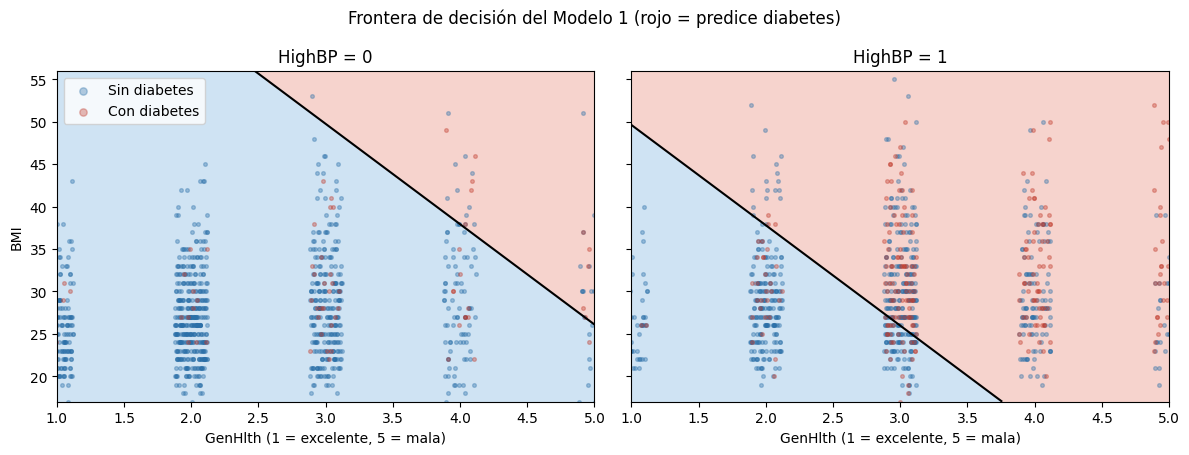

In [ ]:
bmi_lo, bmi_hi = X_train['BMI'].quantile([0.005, 0.995])
g_gen, g_bmi = np.meshgrid(np.linspace(1, 5, 200), np.linspace(bmi_lo, bmi_hi, 200))
muestra = X_test.sample(2000, random_state=42).join(y_test.rename('y'))
rng_j = np.random.default_rng(42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, hbp in zip(axes, [0, 1]):
    grilla = pd.DataFrame({'GenHlth': g_gen.ravel(), 'HighBP': hbp, 'BMI': g_bmi.ravel()})
    z = m1.predict_proba(grilla[cols_m1])[:, 1].reshape(g_gen.shape)
    ax.contourf(g_gen, g_bmi, z >= umbral, levels=[-0.5, 0.5, 1.5], colors=['#cfe3f3', '#f6d3cd'])
    ax.contour(g_gen, g_bmi, z, levels=[umbral], colors='k', linewidths=1.5)
    sub = muestra[muestra['HighBP'] == hbp]
    for clase, color, nom in [(0, '#2a6fa8', 'Sin diabetes'), (1, '#c0392b', 'Con diabetes')]:
        s = sub[sub['y'] == clase]
        ax.scatter(s['GenHlth'] + rng_j.uniform(-0.12, 0.12, len(s)), s['BMI'],
                   s=7, alpha=0.35, color=color, label=nom)
    ax.set_xlim(1, 5); ax.set_ylim(bmi_lo, bmi_hi)
    ax.set_xlabel('GenHlth (1 = excelente, 5 = mala)'); ax.set_title(f'HighBP = {hbp}')
axes[0].set_ylabel('BMI'); axes[0].legend(markerscale=2, loc='upper left')
fig.suptitle('Frontera de decisión del Modelo 1 (rojo = predice diabetes)')
plt.tight_layout(); plt.show()

#5.5. Frontera de decisión

Figura 5. Frontera de decisión de la regresión logística para GenHlth, BMI y HighBP. La visualización representa las regiones donde el modelo predice la clase negativa o positiva, manteniendo separados los distintos valores de HighBP.

La frontera de decisión es lineal porque la regresión logística combina las variables predictoras mediante una función lineal y transforma el resultado en una probabilidad. Al utilizar un umbral de 0,208, la separación entre las regiones de predicción se desplaza respecto de la que se obtendría con el umbral predeterminado de 0,5.

La figura muestra una superposición considerable entre observaciones de ambas clases. Existen casos positivos dentro de regiones clasificadas como negativas y casos negativos dentro de regiones clasificadas como positivas. Esto evidencia que las tres variables utilizadas no permiten separar perfectamente las clases mediante una frontera lineal.

Además, el estado general de salud y el índice de masa corporal no explican por sí solos todas las diferencias entre las observaciones. La presencia de otras variables relevantes y de relaciones potencialmente no lineales puede limitar el desempeño de este modelo

#5.6. Conclusión de la evaluación

Los resultados indican que la regresión logística supera el comportamiento de referencia aleatorio en las métricas de discriminación. Sin embargo, su capacidad de clasificación sigue limitada por la superposición entre las clases y por la cantidad de falsos positivos.

La selección del umbral permite modificar el equilibrio entre recall y precision, pero no elimina las limitaciones del modelo. En un contexto de tamizaje, donde podría ser más importante no dejar casos positivos sin detectar, sería razonable priorizar el recall y aceptar una mayor cantidad de falsas alarmas. Esta decisión debe justificarse según el objetivo del proyecto y no constituye un criterio de diagnóstico clínico.

Por estos motivos, la regresión logística se considera una primera referencia útil, pero deja margen para investigar modelos capaces de representar relaciones no lineales e interacciones entre variables. Esta motivación conduce al desarrollo y evaluación de un segundo modelo de Machine Learning.

### ¿Qué variables usamos?

Comparamos tres conjuntos de variables con el **mismo modelo** (regresión logística sin regularización, con `balanced`) y la **misma CV**. Lo único que cambia es la lista de variables.

| Conjunto | Variables | Cómo se armó |
|---|---|---|
| **A** | 21 (todas) | Sin descartar nada |
| **B** | 10 | Las más asociadas con el objetivo en el análisis exploratorio: `GenHlth`, `HighBP`, `DiffWalk`, `BMI`, `HighChol`, `Age`, `HeartDiseaseorAttack`, `PhysHlth`, `Income`, `Education` |
| **C** | 15 | Las 21 menos las de correlación casi nula (menor a ~0,05): `Smoker`, `Sex`, `AnyHealthcare`, `NoDocbcCost`, `Fruits`, `Veggies` |

**Preprocesamiento (dentro de un Pipeline)**
- Las variables numéricas y ordinales (`BMI`, `MentHlth`, `PhysHlth`, `GenHlth`, `Age`, `Education`, `Income`) se **escalan** para que todas queden en una escala comparable; esto ayuda a la regresión logística.
- Las variables binarias (0/1) se dejan como están. No usamos one-hot porque duplicaría columnas sin aportar nada, y las ordinales ya tienen un orden natural.
- Todo va **dentro del Pipeline**: el escalado se "aprende" solo con los datos de entrenamiento de cada fold, y así no hay fuga de información.

**Control extra**: B y C los elegimos mirando el análisis exploratorio, lo que puede sesgar un poco el resultado. Para chequearlo, agregamos un modelo donde el algoritmo (`SelectKBest`, k=10) elige las 10 mejores variables **dentro de cada fold**.

In [ ]:
# --- 1) Definir los conjuntos ---
todas   = list(X_train.columns)
conj_B  = ['GenHlth','HighBP','DiffWalk','BMI','HighChol','Age',
           'HeartDiseaseorAttack','PhysHlth','Income','Education']
debiles = ['Smoker','Sex','AnyHealthcare','NoDocbcCost','Fruits','Veggies']
conj_C  = [c for c in todas if c not in debiles]
conjuntos = {'A: 21 variables': todas,
             'B: 10 más asociadas': conj_B,
             'C: sin señal casi nula': conj_C}

# --- 2) Pipeline: escala numéricas y ordinales; las binarias pasan tal cual ---
a_escalar = ['BMI','MentHlth','PhysHlth','GenHlth','Age','Education','Income']

def armar_pipeline(cols, selector=None):
    prep = ColumnTransformer([('esc', StandardScaler(), [c for c in a_escalar if c in cols])],
                             remainder='passthrough')
    pasos = [('prep', prep)]
    if selector is not None:
        pasos.append(('sel', selector))
    pasos.append(('lr', LogisticRegression(C=np.inf, class_weight='balanced', max_iter=1000)))
    return Pipeline(pasos)

# --- 3) Evaluar los tres conjuntos con la misma CV ---
for nombre, cols in conjuntos.items():
    evaluar(f'LogReg {nombre}', armar_pipeline(cols), X_train[cols])

# Control sin fuga: el algoritmo elige 10 variables DENTRO de cada fold
evaluar('LogReg A + SelectKBest(k=10) dentro del CV',
        armar_pipeline(todas, SelectKBest(f_classif, k=10)), X_train[todas])

# --- 4) Tabla: benchmark + los cuatro modelos, ordenada por PR-AUC ---
display(tabla_pm().loc[tabla_resultados().sort_values('pr_auc', ascending=False).index])

# --- 5) Colinealidad y coeficientes del conjunto A ---
print(X_train[['GenHlth','PhysHlth','DiffWalk']].corr().round(2))
mA = armar_pipeline(todas).fit(X_train[todas], y_train)
nombres = [n.split('__')[1] for n in mA.named_steps['prep'].get_feature_names_out()]
print(pd.Series(mA.named_steps['lr'].coef_[0], index=nombres).sort_values().round(2))

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
LogReg A: 21 variables,0.718 ± 0.002,0.732 ± 0.002,0.32 ± 0.001,0.754 ± 0.008,0.449 ± 0.002,0.807 ± 0.001,0.404 ± 0.006
LogReg C: sin señal casi nula,0.717 ± 0.002,0.732 ± 0.002,0.32 ± 0.001,0.754 ± 0.007,0.449 ± 0.002,0.805 ± 0.001,0.402 ± 0.006
LogReg B: 10 más asociadas,0.716 ± 0.002,0.729 ± 0.002,0.318 ± 0.002,0.749 ± 0.006,0.446 ± 0.002,0.802 ± 0.001,0.398 ± 0.006
LogReg A + SelectKBest(k=10) dentro del CV,0.716 ± 0.002,0.729 ± 0.002,0.318 ± 0.002,0.749 ± 0.006,0.446 ± 0.002,0.802 ± 0.001,0.398 ± 0.006
Modelo 1: LogReg por defecto (4 var.),0.849 ± 0.001,0.539 ± 0.001,0.53 ± 0.014,0.093 ± 0.002,0.158 ± 0.003,0.776 ± 0.001,0.369 ± 0.003
Modelo 1b: LogReg por defecto + balanced (4 var.),0.696 ± 0.001,0.707 ± 0.002,0.297 ± 0.001,0.722 ± 0.006,0.421 ± 0.002,0.776 ± 0.001,0.367 ± 0.003
Dummy mayoritaria,0.847 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.5 ± 0.0,0.153 ± 0.0


          GenHlth  PhysHlth  DiffWalk
GenHlth      1.00      0.52      0.45
PhysHlth     0.52      1.00      0.47
DiffWalk     0.45      0.47      1.00
HvyAlcoholConsump      -0.79
Income                 -0.10
PhysHlth               -0.06
MentHlth               -0.04
Education              -0.02
Fruits                 -0.02
Smoker                 -0.02
PhysActivity           -0.01
Veggies                -0.01
NoDocbcCost             0.00
AnyHealthcare           0.11
DiffWalk                0.12
Stroke                  0.15
HeartDiseaseorAttack    0.23
Sex                     0.29
Age                     0.44
BMI                     0.47
HighChol                0.57
GenHlth                 0.57
HighBP                  0.72
CholCheck               1.31
dtype: float64



**Conclusiones**
1. **Los tres conjuntos superan claramente al benchmark** (ROC-AUC de 0,75 a ~0,80; PR-AUC de 0,33 a ~0,40), mejorando recall y precisión a la vez.
2. **Las diferencias entre A, B y C son mínimas** (0,002 a 0,005 de ROC-AUC). En PR-AUC quedan dentro del desvío entre folds.
3. **`SelectKBest` da lo mismo que B**: haber elegido B a mano no sesgó los resultados.
4. Con resultados tan parecidos, por **parsimonia** conviene el conjunto más chico que no pierda desempeño: **C** casi no pierde nada respecto de A con 6 variables menos; **B** serviría si quisiéramos un cuestionario muy corto, a costa de ~0,005 de ROC-AUC.

**Conjunto elegido por el grupo: [COMPLETAR]** — Justificación: [COMPLETAR]

### Colinealidad: por qué complica la interpretación de coeficientes

`GenHlth`, `PhysHlth` y `DiffWalk` están correlacionadas entre sí (entre 0,45 y 0,52): miden en parte lo mismo.

Un coeficiente dice *"cuánto cambia el riesgo al subir esta variable, **manteniendo las demás constantes**"*. Si dos variables se mueven juntas, el modelo no puede separar bien qué parte del efecto es de cada una. **Esto no empeora las predicciones** (por eso A, B y C rinden igual), pero sí dificulta **interpretar** los coeficientes. Ejemplos de nuestros resultados:
- **Signo invertido**: `PhysHlth` tiene coeficiente −0,06, pero en el análisis exploratorio más días de mala salud física se asociaban con **más** diabetes. Lo que pasa es que `GenHlth` y `DiffWalk` ya contienen esa información, y `PhysHlth` no aporta nada propio. Algo parecido ocurre con `MentHlth` (−0,04).
- **Coeficiente más chico de lo esperado**: `DiffWalk` tenía una correlación alta con el objetivo (0,21), pero su coeficiente es 0,12 porque otras variables absorben su efecto.
- **El valor cambia con el conjunto**: `GenHlth` valía 0,74 en el modelo de 2 variables y 0,57 en el de 21.

**Cuándo molesta y cuándo no**
- **No molesta** si solo queremos **predecir**.
- **Molesta** si queremos decir *"la variable X es la más importante"* o *"cada punto más de X sube el riesgo en tanto"*.

### Dos coeficientes para interpretar con cuidado
- **`CholCheck` = 1,31** (el más grande). Quienes no se hicieron un control de colesterol son pocos y casi nunca están diagnosticados. Puede reflejar quién llega a ser diagnosticado, no un riesgo biológico.
- **`HvyAlcoholConsump` = −0,79**. Coincide con el análisis exploratorio, pero no significa que beber proteja: probablemente quienes tienen diabetes dejan de tomar.

Todos los coeficientes son **asociaciones, no causas**, y los datos son autorreportados.

**Próximos pasos**: ajustar el umbral de decisión, evaluar el primer modelo con los resultados finales (consigna 5) y pasar al segundo modelo con regularización (consigna 6).

In [ ]:
# --- 0) Coeficientes del modelo C (para decidir con sus propios números) ---
mC = armar_pipeline(conj_C).fit(X_train[conj_C], y_train)
nombres = [n.split('__')[1] for n in mC.named_steps['prep'].get_feature_names_out()]
print(pd.Series(mC.named_steps['lr'].coef_[0], index=nombres).sort_values().round(2))

# --- 1) Variables derivadas (cuentas fila por fila: no filtran información) ---
def agregar_derivadas(X):
    X = X.copy()
    X['BMI2'] = X['BMI'] ** 2
    X['HighBP_x_HighChol'] = X['HighBP'] * X['HighChol']
    X['Age_x_GenHlth']     = X['Age'] * X['GenHlth']
    X['BMI_x_Age']         = X['BMI'] * X['Age']
    X['GenHlth_x_HighBP']  = X['GenHlth'] * X['HighBP']
    for a in range(2, 14):                       # Age en categorías (la 1 es la base)
        X[f'Age_{a}'] = (X['Age'] == a).astype(float)
    return X

X_train_ext = agregar_derivadas(X_train)
extra_escalar = ['BMI2', 'Age_x_GenHlth', 'BMI_x_Age', 'GenHlth_x_HighBP']
a_escalar = list(dict.fromkeys(a_escalar + extra_escalar))   # agrega sin duplicar

# --- 2) Variantes del conjunto C ---
quitar = ['PhysActivity', 'Education', 'MentHlth', 'PhysHlth']
E1 = [c for c in conj_C if c not in quitar]
E2 = E1 + ['Sex']
E3 = E2 + ['BMI2']
E4 = [c for c in E2 if c != 'Age'] + [f'Age_{a}' for a in range(2, 14)]
E5 = E2 + ['HighBP_x_HighChol', 'Age_x_GenHlth', 'BMI_x_Age', 'GenHlth_x_HighBP']
variantes = {'E1: C sin 4 de coef. ~0': E1, 'E2: E1 + Sex': E2, 'E3: E2 + BMI²': E3,
             'E4: E2 con Age en categorías': E4, 'E5: E2 + 4 interacciones': E5}

for nombre, cols in variantes.items():
    evaluar(f'LogReg {nombre}', armar_pipeline(cols), X_train_ext[cols])

# --- 3) Tabla comparada con C ---
mostrar = ['LogReg C: sin señal casi nula'] + [f'LogReg {n}' for n in variantes]
display(tabla_pm().loc[mostrar, ['recall', 'precision', 'roc_auc', 'pr_auc']])

HvyAlcoholConsump      -0.77
Income                 -0.07
PhysHlth               -0.06
MentHlth               -0.05
Education              -0.03
PhysActivity           -0.01
DiffWalk                0.10
Stroke                  0.16
HeartDiseaseorAttack    0.28
Age                     0.44
BMI                     0.47
HighChol                0.56
GenHlth                 0.58
HighBP                  0.73
CholCheck               1.31
dtype: float64


,recall,precision,roc_auc,pr_auc
LogReg C: sin señal casi nula,0.754 ± 0.007,0.32 ± 0.001,0.805 ± 0.001,0.402 ± 0.006
LogReg E1: C sin 4 de coef. ~0,0.753 ± 0.006,0.319 ± 0.001,0.805 ± 0.001,0.402 ± 0.006
LogReg E2: E1 + Sex,0.754 ± 0.006,0.32 ± 0.001,0.806 ± 0.001,0.403 ± 0.006
LogReg E3: E2 + BMI²,0.757 ± 0.007,0.321 ± 0.002,0.809 ± 0.001,0.419 ± 0.005
LogReg E4: E2 con Age en categorías,0.757 ± 0.004,0.32 ± 0.002,0.809 ± 0.001,0.411 ± 0.006
LogReg E5: E2 + 4 interacciones,0.764 ± 0.004,0.317 ± 0.002,0.808 ± 0.001,0.409 ± 0.006
